In [1]:
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
%config InlineBackend.figure_format = 'retina'
sns.set_theme()

main_color = "#379665"

# 1. Data exploration and initial analysis

In [2]:
df_raw = pd.read_csv("data/acdc_dataset.csv", sep=";", index_col="member_id")
df = df_raw.copy()
df_raw.head()


,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,
CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,...,False,True,0,False,True,True,False,False,2,4477.97
CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,...,False,False,0,True,False,False,False,False,0,165.86
CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,...,False,False,0,False,False,False,False,False,1,4486.17
CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,...,False,False,0,False,False,False,False,False,0,258.63
CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,...,False,False,0,False,False,True,False,False,0,335.74


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  str    
 2   industry                     15465 non-null  str    
 3   country                      15035 non-null  str    
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  str    
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  str    
 9   membership_end               15465 non-null  str    
 10  last_badge_swipe             15465 non-null  str    
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_visits     

In [4]:
df_raw.columns

Index(['age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='str')

In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


In [6]:
df_raw.describe(include="bool").T

,count,unique,top,freq
is_team_account,15465,2,False,11112
uses_meeting_rooms,15465,2,False,10202
uses_event_space,15465,2,False,13624
uses_guest_passes,15465,2,False,12651
uses_mail_handling,15465,2,False,11901
uses_phone_booths,15465,2,False,11469
uses_day_passes,15465,2,False,12069
uses_storage,15465,2,False,13169
uses_bike_locker,15465,2,False,15439


In [7]:
df_raw.describe(include="str").T
#plan tier should only have 5 unique values
#gender shou have 3: Female, Male, Other

,count,unique,top,freq
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


# 2. Data quality checks

In [8]:
df['membership_start'] = pd.to_datetime(df["membership_start"], format='mixed')
df['membership_end'] = pd.to_datetime(df["membership_end"], format='mixed')
df['last_badge_swipe'] = pd.to_datetime(df["last_badge_swipe"], format='mixed')

We turned the variable `lifetime_value` to a float. The variable had symbols that made them into an object type.

In [9]:
df["lifetime_value"] = (
    df["lifetime_value"]
    .str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float)
)

In [10]:
df_raw["uses_print"].unique()

array([0, 1])

`uses_print` only has the values 1 and 0, so we turn it into a boolean type.

In [11]:
df["uses_print"] = df["uses_print"].astype("bool")
df["uses_print"].dtype

dtype('bool')

In [12]:
df.isna().sum()[lambda s: s > 0]

age                     558
gender                  530
country                 430
plan_tier               105
meeting_room_hours     1298
guest_passes_issued    1271
lifetime_value         1040
dtype: int64

In [13]:
#Turning object values to lower case
cols_object = df.select_dtypes(include="str").columns
df[cols_object] = df[cols_object].apply(lambda s: s.str.lower())

print(f"Gender unique values: {df["gender"].unique()}")
print(f"Country unique values: {df["country"].unique()}")
print(f"Plan tier unique values: {df["plan_tier"].unique()}")
print(f"Industry unique values: {df["industry"].unique()}")

Gender unique values: <ArrowStringArray>
['female', 'male', 'f', 'other', nan, ' female', 'm', ' male', ' other', 'o']
Length: 10, dtype: str
Country unique values: <ArrowStringArray>
[       'portugal',              'de',  'united kingdom',           'spain',
         'germany',     'netherlands',          'france',              'pt',
  'other (europe)',        'portucal',               nan,              'uk',
         'ireland',              'ie',       'portugal ',     'deutschland',
            'u.k.',              'gb',              'es',              'nl',
          'españa',          'espana', 'the netherlands',              'fr',
         'holland']
Length: 25, dtype: str
Plan tier unique values: <ArrowStringArray>
[          'flex',       'hot_desk', 'dedicated_desk',      'full_time',
 'private_office',       'hot desk',  'dedicateddesk',              nan,
        'hotdesk',       'fulltime',  'privateoffice',      'full time',
 'dedicated desk', 'private office']
Length: 14,

In [14]:
#Replacing gender values
df["gender"] = df["gender"].replace([" female", "f"], "female")
df["gender"] = df["gender"].replace([" male", "m"], "male")
df["gender"] = df["gender"].replace([" other", "o"], "other")

#Replacing country values
df["country"] = df["country"].replace({
    "portucal":"portugal", "portugal ":"portugal", "pt":"portugal",
    "de":"germany", "deutschland":"germany",
    "uk":"united kingdom", "u.k.":"united kingdom", "gb":"united kingdom",
    "es":"spain", "españa":"spain", "espana":"spain",
    "nl":"netherlands", "the netherlands":"netherlands", "holland":"netherlands",
    "fr":"france",
    "ie":"ireland"})

#Replacing Plan tier values
df["plan_tier"] = df["plan_tier"].replace(["hotdesk", "hot desk"], "hot_desk")
df["plan_tier"] = df["plan_tier"].replace(["dedicateddesk", "dedicated desk"], "dedicated_desk")
df["plan_tier"] = df["plan_tier"].replace(["fulltime", "full time"], "full_time")
df["plan_tier"] = df["plan_tier"].replace(["privateoffice", "private office"], "private_office")

#Replacing Industry values
df["industry"] = df["industry"].replace(["it", "tech"], "information technology")
df["industry"] = df["industry"].replace(["design & creative", "design/creative"], "design and creative")
df["industry"] = df["industry"].replace(["marketing & pr", "marketing/pr"], "marketing and pr")
df["industry"] = df["industry"].replace(["realestate", "real-estate"], "real estate")

df.describe(include="str").T

,count,unique,top,freq
gender,14935,3,female,7867
industry,15465,11,information technology,3559
country,15035,8,portugal,10508
plan_tier,15360,5,flex,5453


In [15]:
df.duplicated().sum()

np.int64(295)

In [16]:
df = df.drop_duplicates()

In [17]:
non_metric_features = ['gender', 'country', 'industry', 'plan_tier', 'is_team_account',
 'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes',
 'uses_storage', 'uses_bike_locker']

metric_features = df.columns.drop(non_metric_features).to_list()

In [18]:
df.index.duplicated().sum()

np.int64(0)

## Non-metric variables analysis

### Univariate analysis

#### Nominal variables with more than two categories

In [19]:
df.describe(include="str").T

,count,unique,top,freq
gender,14650,3,female,7707
industry,15170,11,information technology,3489
country,14748,8,portugal,10309
plan_tier,15068,5,flex,5350


In [20]:
df.select_dtypes(exclude='number').info()

<class 'pandas.DataFrame'>
Index: 15170 entries, CW000001 to CW015000
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   gender              14650 non-null  str           
 1   industry            15170 non-null  str           
 2   country             14748 non-null  str           
 3   is_team_account     15170 non-null  bool          
 4   plan_tier           15068 non-null  str           
 5   membership_start    15170 non-null  datetime64[us]
 6   membership_end      15170 non-null  datetime64[us]
 7   last_badge_swipe    15170 non-null  datetime64[us]
 8   uses_meeting_rooms  15170 non-null  bool          
 9   uses_event_space    15170 non-null  bool          
 10  uses_guest_passes   15170 non-null  bool          
 11  uses_print          15170 non-null  bool          
 12  uses_mail_handling  15170 non-null  bool          
 13  uses_phone_booths   15170 non-null  bool          
 

In [21]:
df["gender"].unique()

<ArrowStringArray>
['female', 'male', 'other', nan]
Length: 4, dtype: str

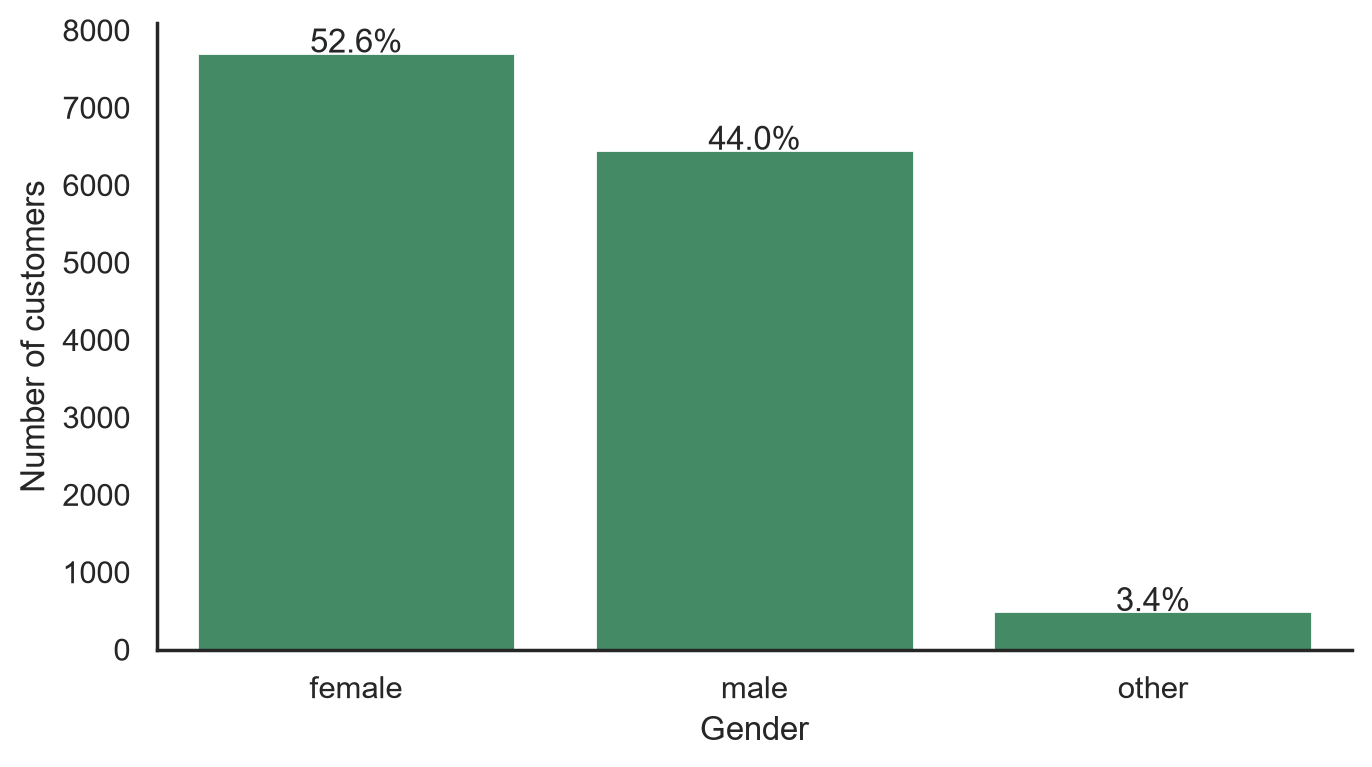

In [22]:
# Single Non-Metric variable bar plot
gender = df["gender"].reset_index(drop=True)

sns.set_style("white")

plt.figure(figsize=(7, 4))

ax = sns.countplot(
    x=gender,
    color=main_color,
    order=gender.value_counts().index
)

# Add percentages
total = gender.count()

for bar in ax.patches:
    percentage = bar.get_height() / total * 100
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        f"{percentage:.1f}%",
        ha="center"
    )

plt.xlabel("Gender")
plt.ylabel("Number of customers")
sns.despine()
plt.tight_layout()
plt.show()

The distribution across gender categories is relatively balanced, with females representing 52.7% of customers, males 44.0%, and other genders 3.3%. Although females constitute a slight majority, there is no substantial imbalance between the female and male categories.

In [23]:
df["industry"].unique()

<ArrowStringArray>
['information technology',              'education',                  'legal',
                 'health',                'unknown',                  'other',
             'consulting',    'design and creative',                'finance',
       'marketing and pr',            'real estate']
Length: 11, dtype: str

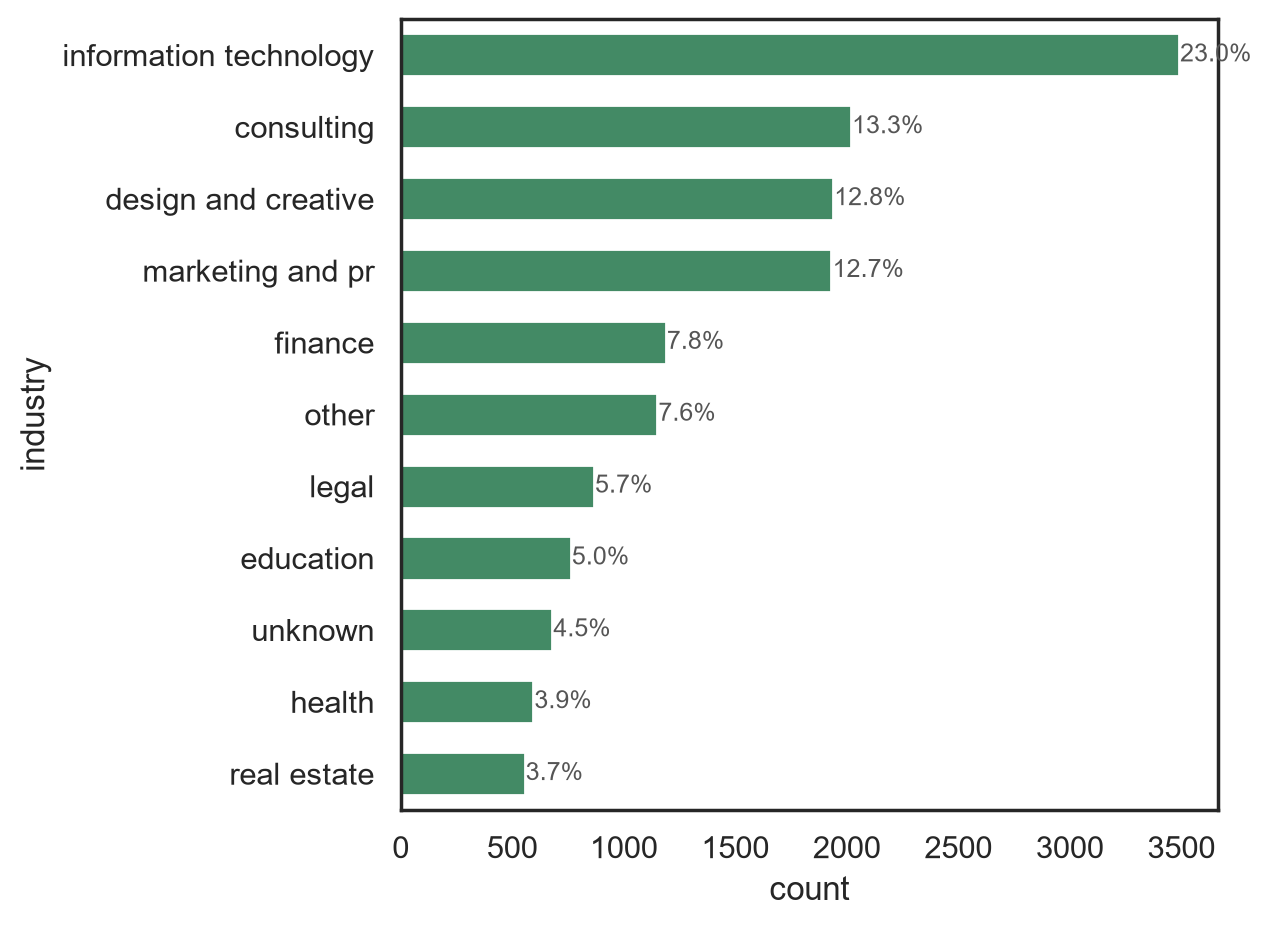

In [24]:
ax = sns.countplot(
    y=df["industry"],
    color=main_color,
    width=0.6,
    order=df["industry"].value_counts().index
)

total = df["industry"].count()

for bar in ax.patches:
    pct = bar.get_width() / total * 100
    ax.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height()/2,
        f"{pct:.1f}%",
        va="center",
        fontsize=9,
        color="#555555"
    )

plt.tight_layout()
plt.show()

The majority of customers work in IT, consulting, design and creative industries, and marketing.

Overall, the distribution of occupations is relatively heterogeneous, suggesting that there is no clearly defined consumer profile based on occupation. Customers range from real estate professionals to individuals working in design and creative fields, reflecting a diverse customer base.

It is also worth noting that the occupation is unknown for 4.5% of customers.

In [25]:
df["country"].unique()

<ArrowStringArray>
[      'portugal',        'germany', 'united kingdom',          'spain',
    'netherlands',         'france', 'other (europe)',              nan,
        'ireland']
Length: 9, dtype: str

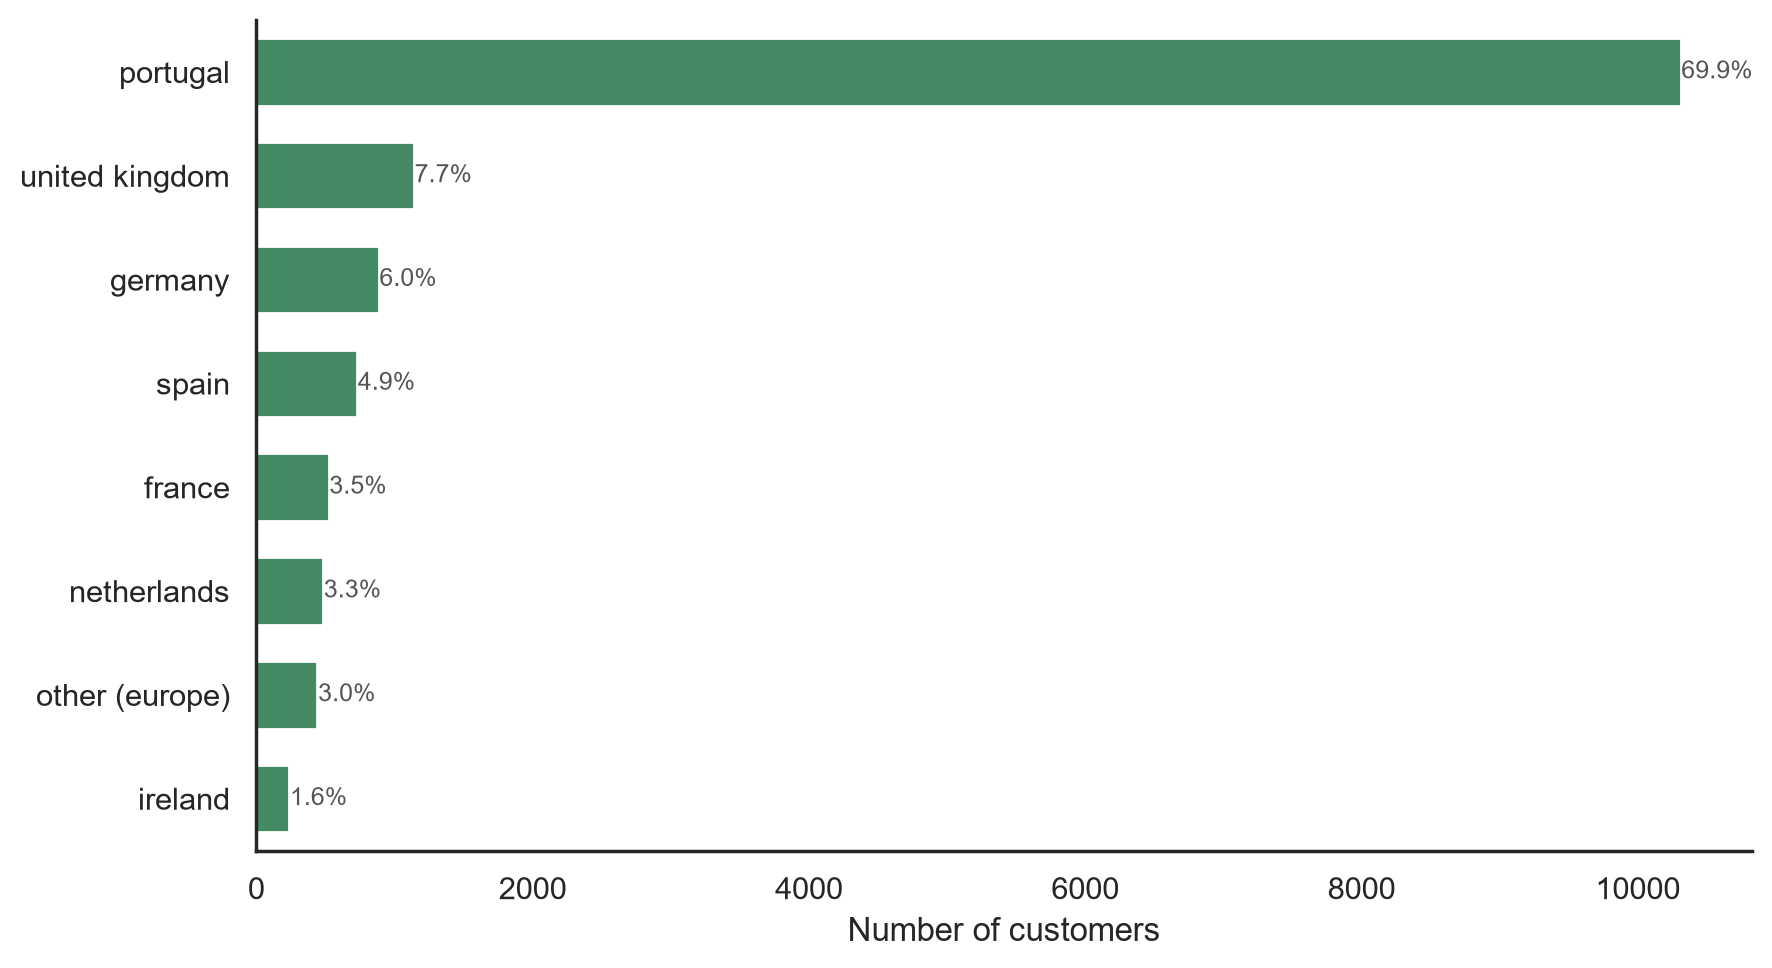

In [26]:
country = df["country"].reset_index(drop=True)

plt.figure(figsize=(9, 5))

ax = sns.countplot(
    y=country,
    color=main_color,
    width=0.65,
    order=country.value_counts().index
)

total = country.count()

for bar in ax.patches:
    pct = bar.get_width() / total * 100
    ax.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        fontsize=9,
        color="#555555"
    )

plt.xlabel("Number of customers")
plt.ylabel("")
sns.despine()
plt.tight_layout()
plt.show()

Approximately 69.9% of customers are from Portugal, indicating a considerable geographical imbalance. This concentration may limit the identification of geographically distinct consumer segments. 

In [27]:
df["plan_tier"].unique()

<ArrowStringArray>
['flex', 'hot_desk', 'dedicated_desk', 'full_time', 'private_office', nan]
Length: 6, dtype: str

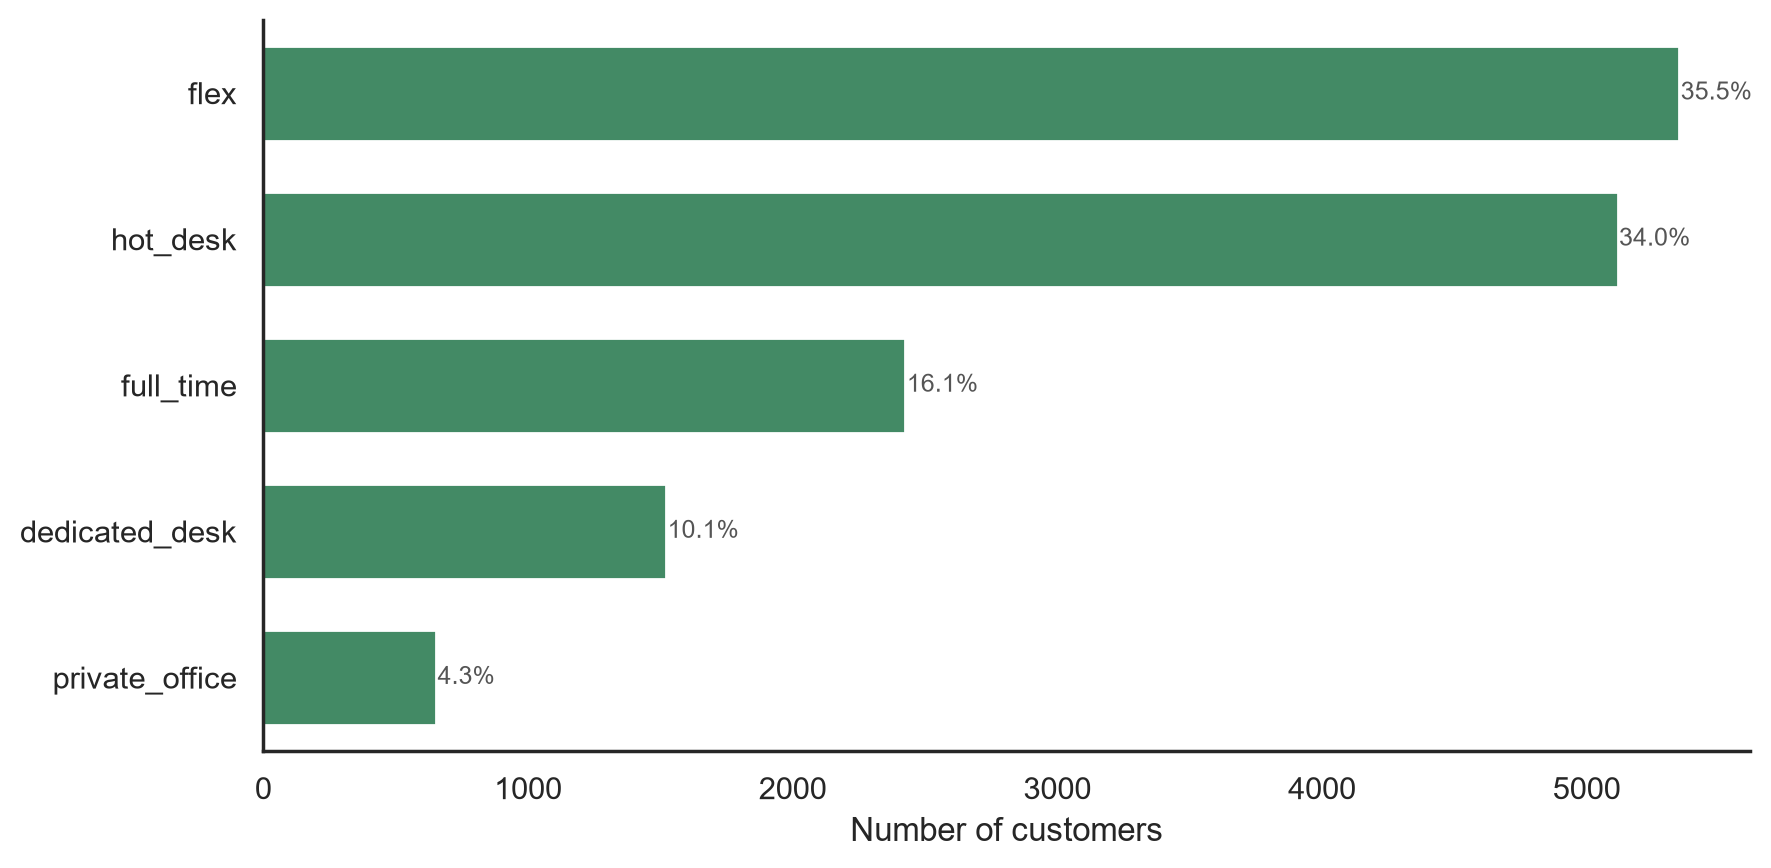

In [28]:
plan_tier = df["plan_tier"].reset_index(drop=True)

plt.figure(figsize=(9, 4.5))

ax = sns.countplot(
    y=plan_tier,
    color=main_color,
    width=0.65,
    order=plan_tier.value_counts().index
)

total = plan_tier.count()

for bar in ax.patches:
    pct = bar.get_width() / total * 100
    ax.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        fontsize=9,
        color="#555555"
    )

plt.xlabel("Number of customers")
plt.ylabel("")
sns.despine()
plt.tight_layout()
plt.show()

According to the *Metadata* section, coworking services are ranked by price as follows: `hot_desk` < `flex` < `dedicated_desk` < `full_time` < `private_office`. Interestingly, customers show a slight preference for `flex` over `hot_desk`, suggesting that they may value a balance between affordability and flexibility. Overall, customers seem to favour relatively affordable options, while showing less interest in the more expensive services, particularly `private_office`, as expected.

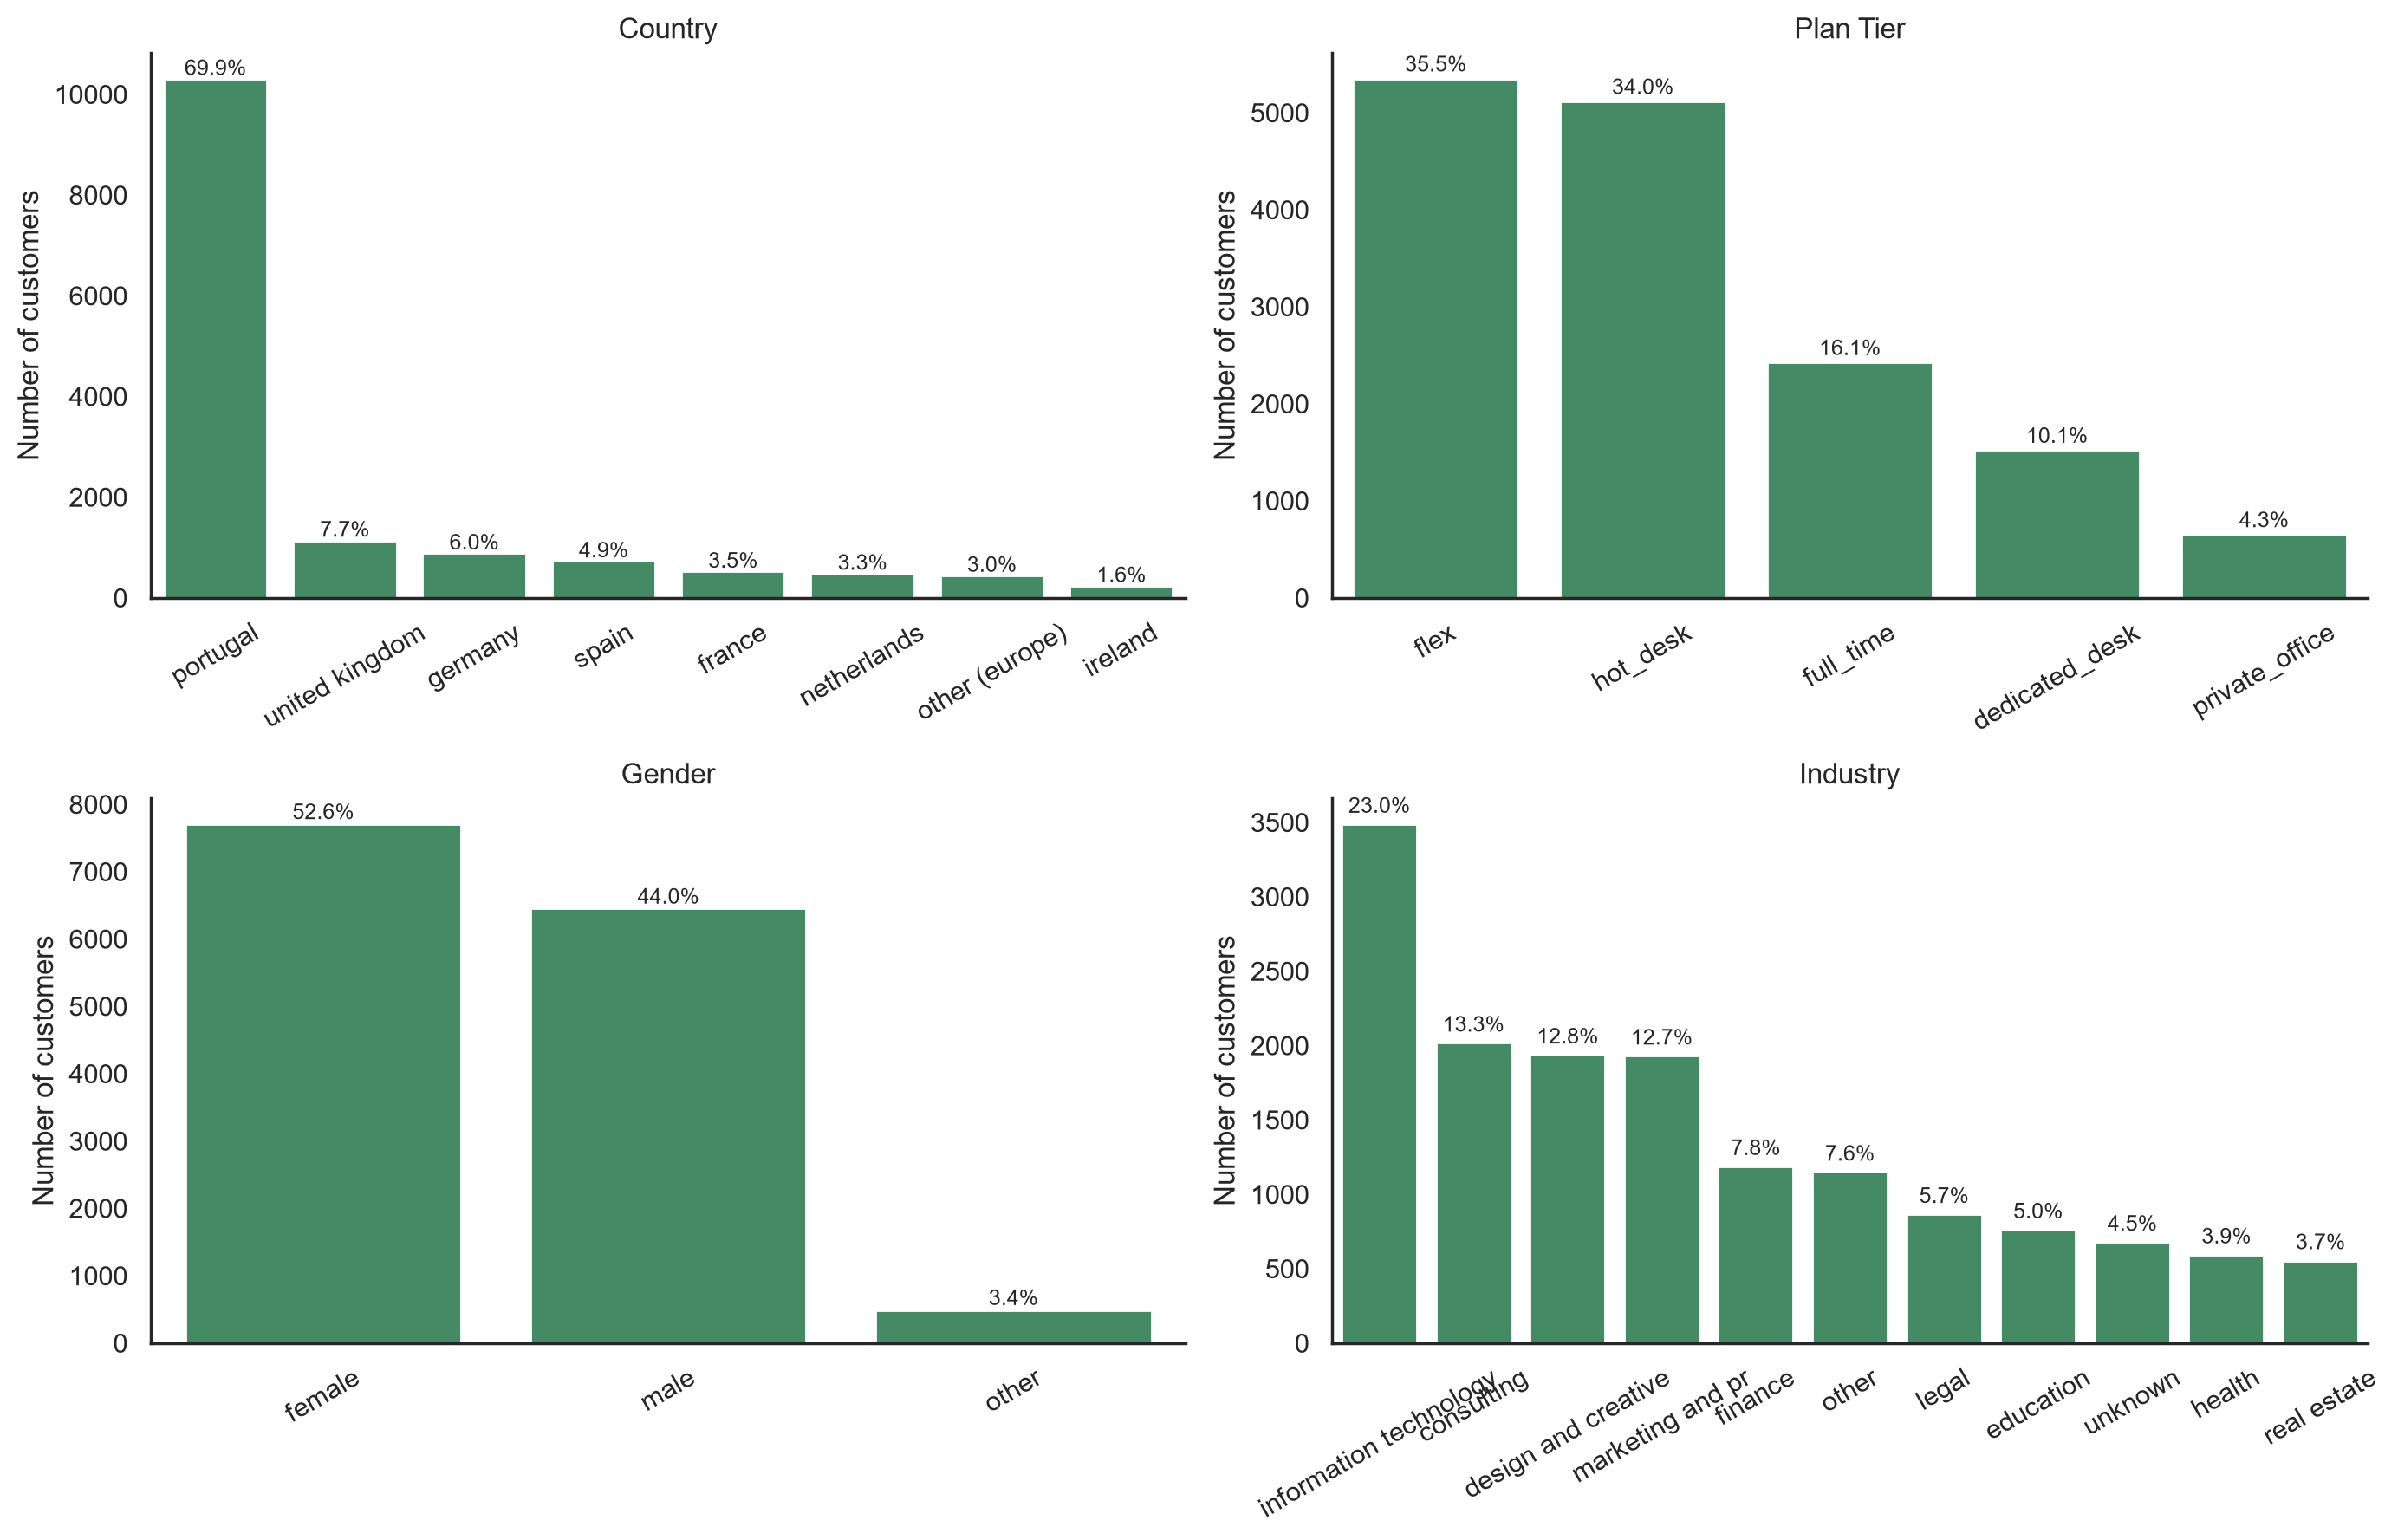

In [29]:
# 2x2 Non-Metric Variables Bar Plots

variables = ["country", "plan_tier", "gender", "industry"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

sns.set_style("white")

for ax, var in zip(axes, variables):

    data = df[var].reset_index(drop=True)
    order = data.value_counts().index
    total = data.count()

    sns.countplot(
        x=data,
        color=main_color,
        order=order,
        ax=ax
    )

    # Add percentages
    for bar in ax.patches:
        percentage = bar.get_height() / total * 100
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + total * 0.005,
            f"{percentage:.1f}%",
            ha="center",
            fontsize=9
        )

    ax.set_title(var.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Number of customers")
    ax.tick_params(axis="x", rotation=30)

    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

The four categorical variables are summarised above, providing a visual overview of the information previously presented and discussed.

#### Binary variables

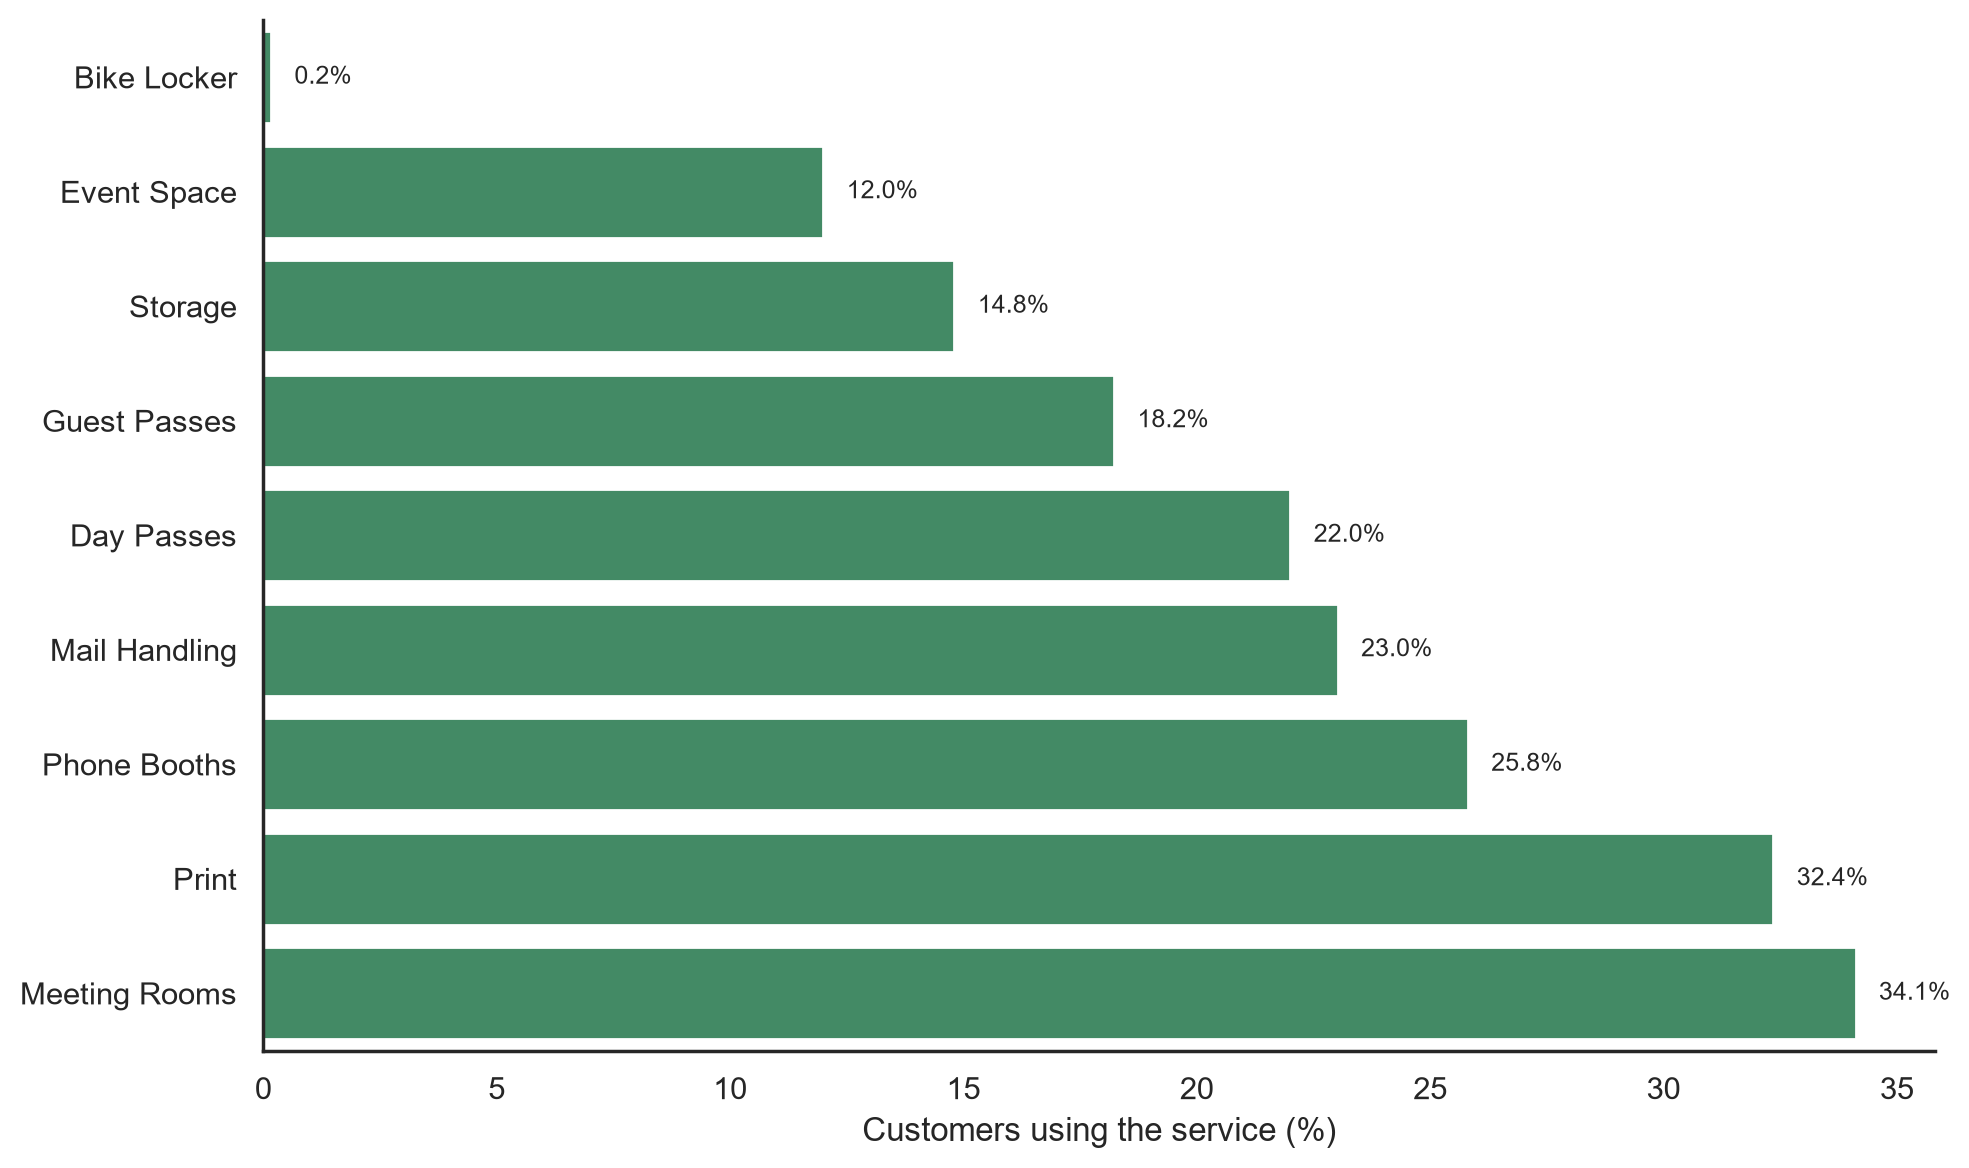

In [30]:
# Binary Variables — Usage Distribution

binary_vars = [
    "uses_meeting_rooms",
    "uses_event_space",
    "uses_guest_passes",
    "uses_print",
    "uses_mail_handling",
    "uses_phone_booths",
    "uses_day_passes",
    "uses_storage",
    "uses_bike_locker"
]

binary_data = (
    df[binary_vars]
    .mean()
    .mul(100)
    .sort_values()
)

sns.set_style("white")

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=binary_data.values,
    y=binary_data.index.str.replace("uses_", "").str.replace("_", " ").str.title(),
    color=main_color
)

for bar in ax.patches:
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center",
        fontsize=9
    )

plt.xlabel("Customers using the service (%)")
plt.ylabel("")
sns.despine()
plt.tight_layout()
plt.show()

Customers do not appear to make frequent use of these additional services, which may be related to their preference for lower-cost plans. One possible explanation is that cheaper plans offer access to fewer services than more expensive alternatives. However, this relationship requires further investigation. We will revisit this hypothesis in the next section, where we analyse the relationships between non-metric variables (categorical vs. categorical, categorical vs. binary, and binary vs. binary).

### Bivariate analysis

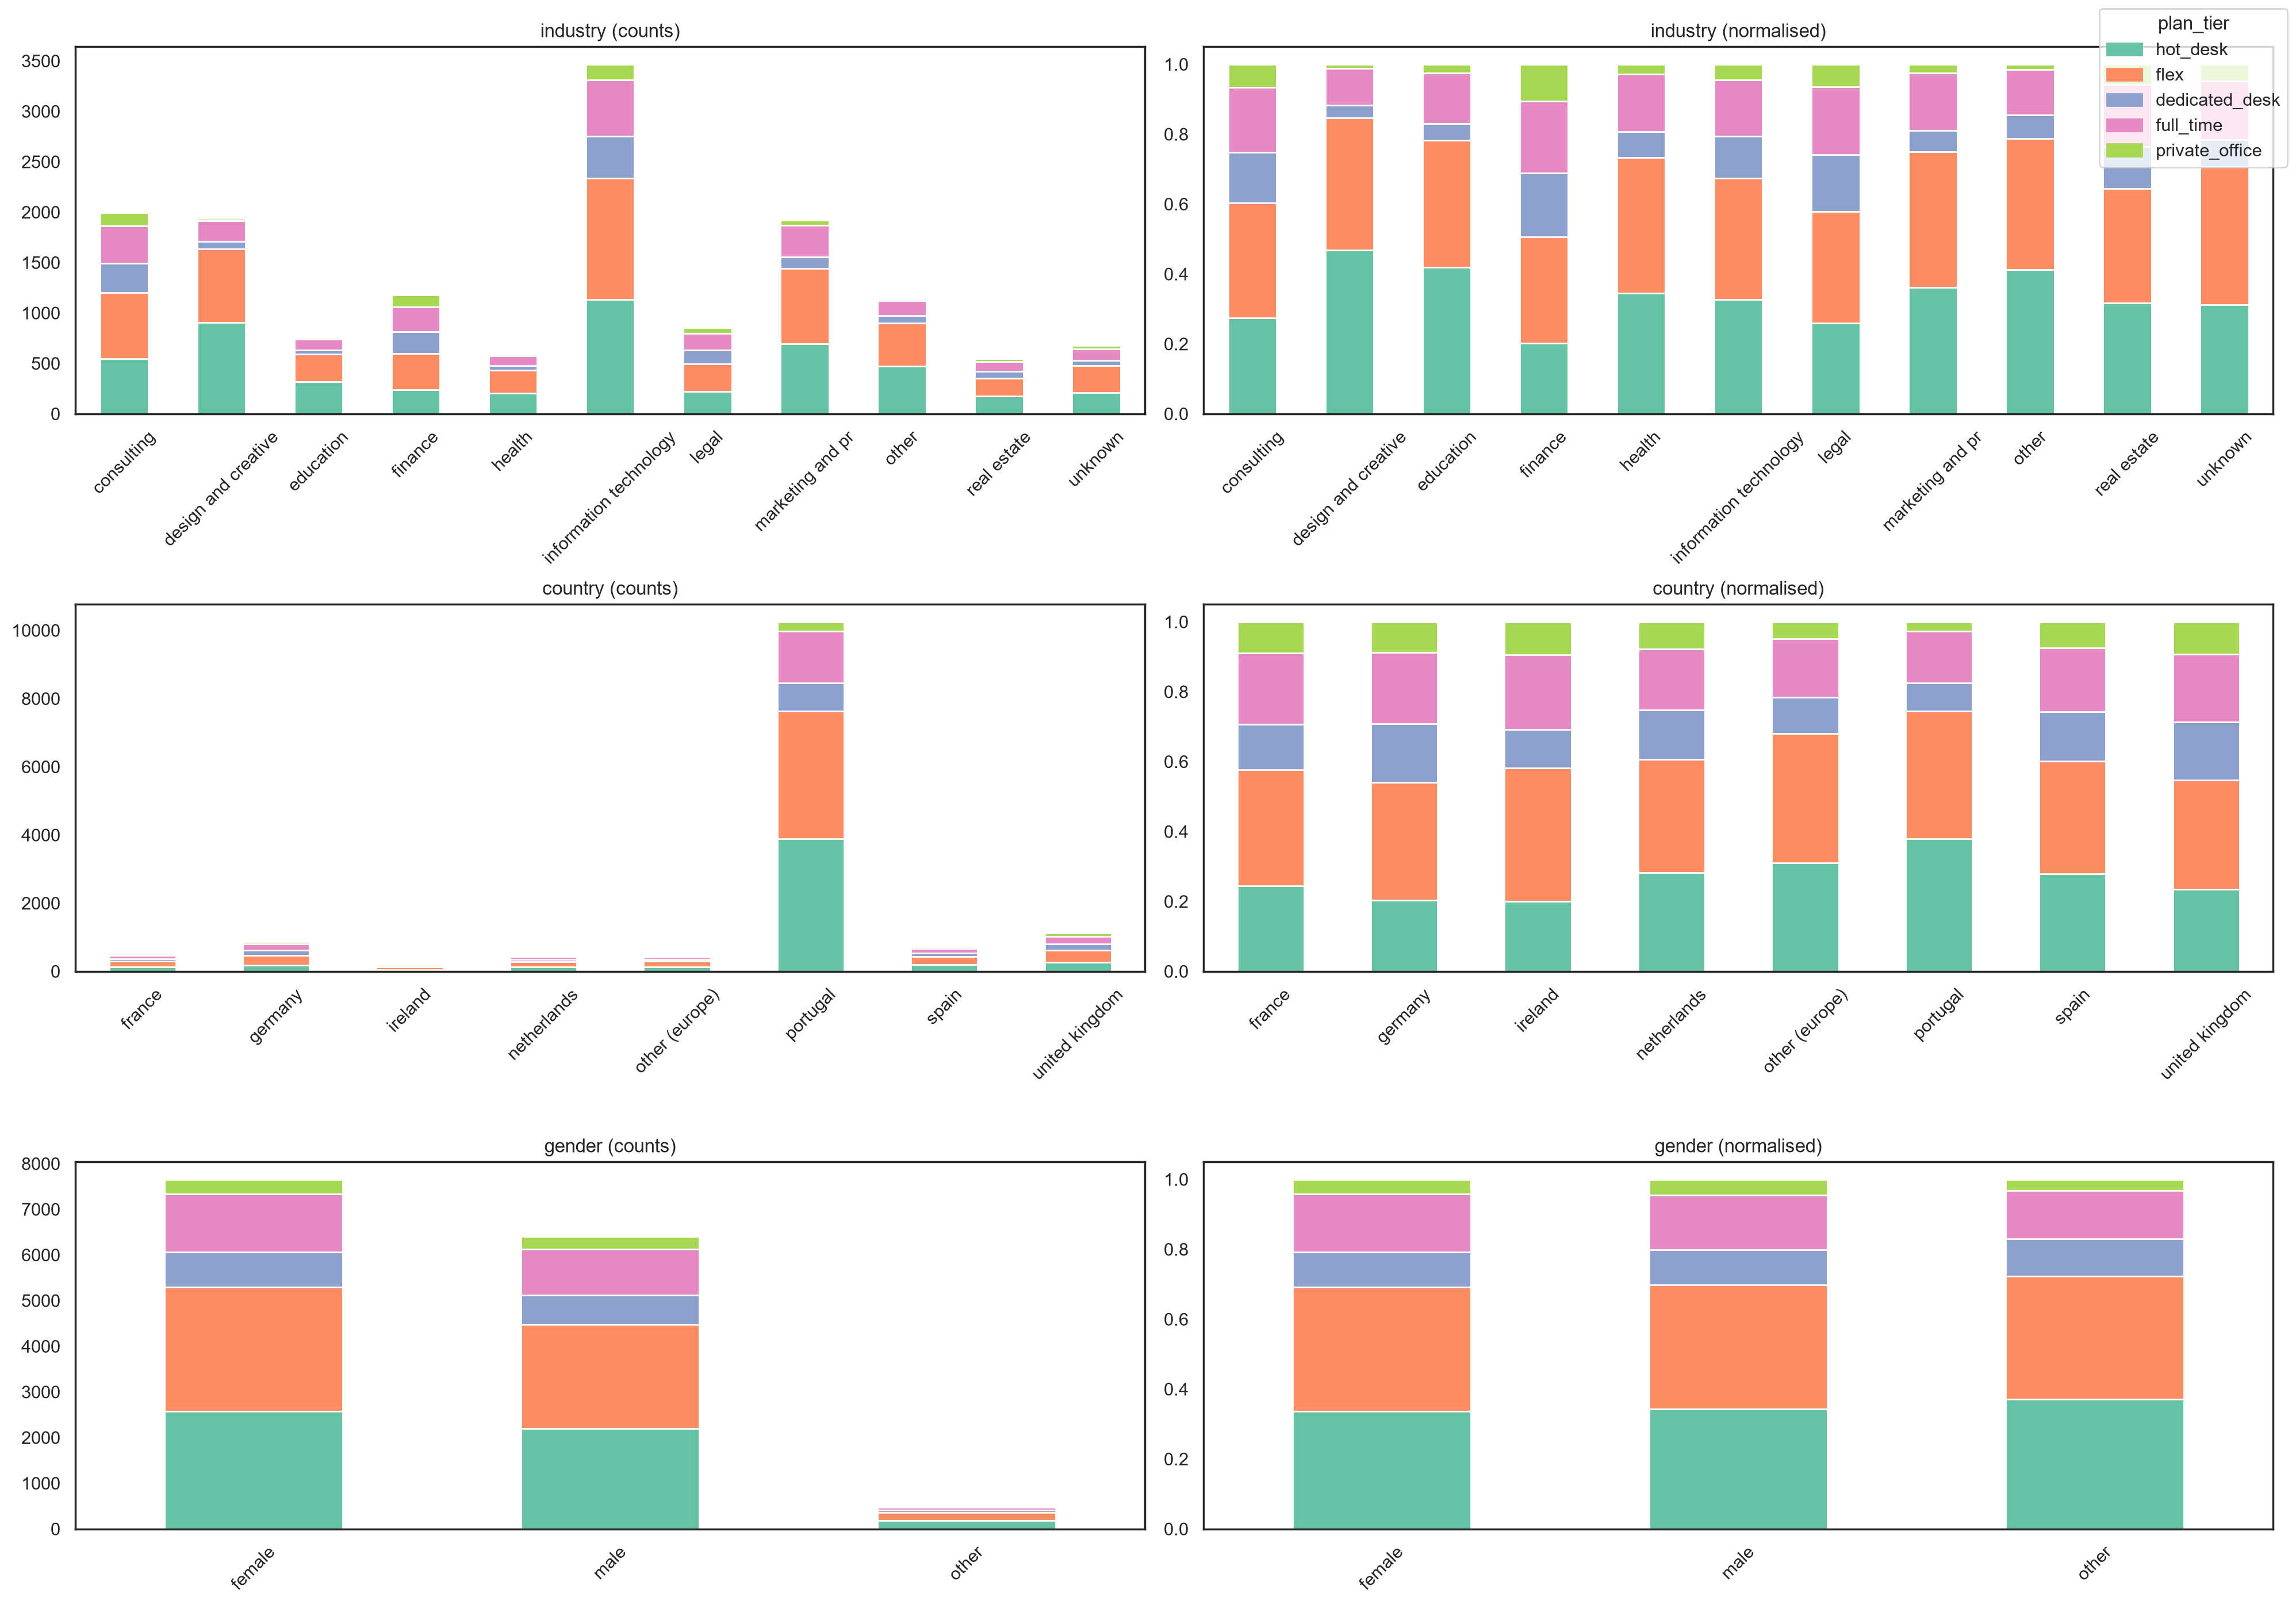

In [31]:
target = "plan_tier"
object_features = ["industry", "country", "gender"]

tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]
n_classes = len(tier_order)
tier_colors = sns.color_palette("Set2", n_classes)   # clássica, bem distintaa

fig, axes = plt.subplots(len(object_features), 2, figsize=(20, 14))

for row, feat in zip(axes, object_features):
    ct_counts = pd.crosstab(df[feat], df[target])[tier_order]
    ct_norm = pd.crosstab(df[feat], df[target], normalize="index")[tier_order]

    ct_counts.plot(kind="bar", stacked=True, color=tier_colors, ax=row[0], legend=False)
    row[0].set_title(f"{feat} (counts)")

    ct_norm.plot(kind="bar", stacked=True, color=tier_colors, ax=row[1], legend=False)
    row[1].set_title(f"{feat} (normalised)")

    for ax in row:
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=45)

# single legend for the whole figure
from matplotlib.patches import Patch
handles = [Patch(color=c, label=t) for c, t in zip(tier_colors, tier_order)]
fig.legend(handles=handles, title=target, loc="upper right")

plt.tight_layout()

os.makedirs(os.path.join('..', 'figures', 'eda'), exist_ok=True)
plt.savefig(os.path.join('..', 'figures', 'eda', 'categorical_variables_crosstab.png'), dpi=200)

plt.show()

**Industry**
- Contrary to what we might expect, the industry with the highest share of customers on the most expensive plan, `private_office`, is `finance` (it would be intuitive to think it would be IT), although it does not stand out dramatically from the rest.
- In practically all industries, roughly 65–85% of customers choose one of the two cheapest plans (`hot_desk` or `flex`). The exceptions are `consulting`, `finance` and `legal`.
- `other` and `unknown` behave similarly overall. There is only a slight difference in how they split the more expensive plans: `unknown` favours `full_time` more, while `other` favours `dedicated_desk` more.

**Country**
- Among the non-Portuguese countries, plan choice is quite similar.
- Portugal stands out. Only about 3% of Portuguese customers choose `private_office`, compared with roughly 8–9% in most other countries, which is the lowest share and a clear difference.
- Portuguese customers also lean towards the cheapest plans: `hot_desk` and `flex` together account for about 74%, against roughly 54–60% elsewhere.
- Since 69.9% of customers in the dataset are Portuguese, this behaviour largely drives the overall distribution of plans.
- The percentages for the other countries are based on far fewer customers and are therefore less stable.

**Gender**
- Gender shows practically no relationship with plan choice. The distribution across plan tiers is almost identical for `female` and `male` customers.
- The small differences for `other` are likely due to its small sample size.
- Gender therefore seems unlikely to help distinguish customer segments with respect to the plan tier chosen.

**Across all variables**
- In every chart, customers clearly choose `full_time` more often than the immediately cheaper plan, `dedicated_desk` (the pink section is always larger than the blue one, regardless of the variable analysed).

#### Binary vs. binary variables

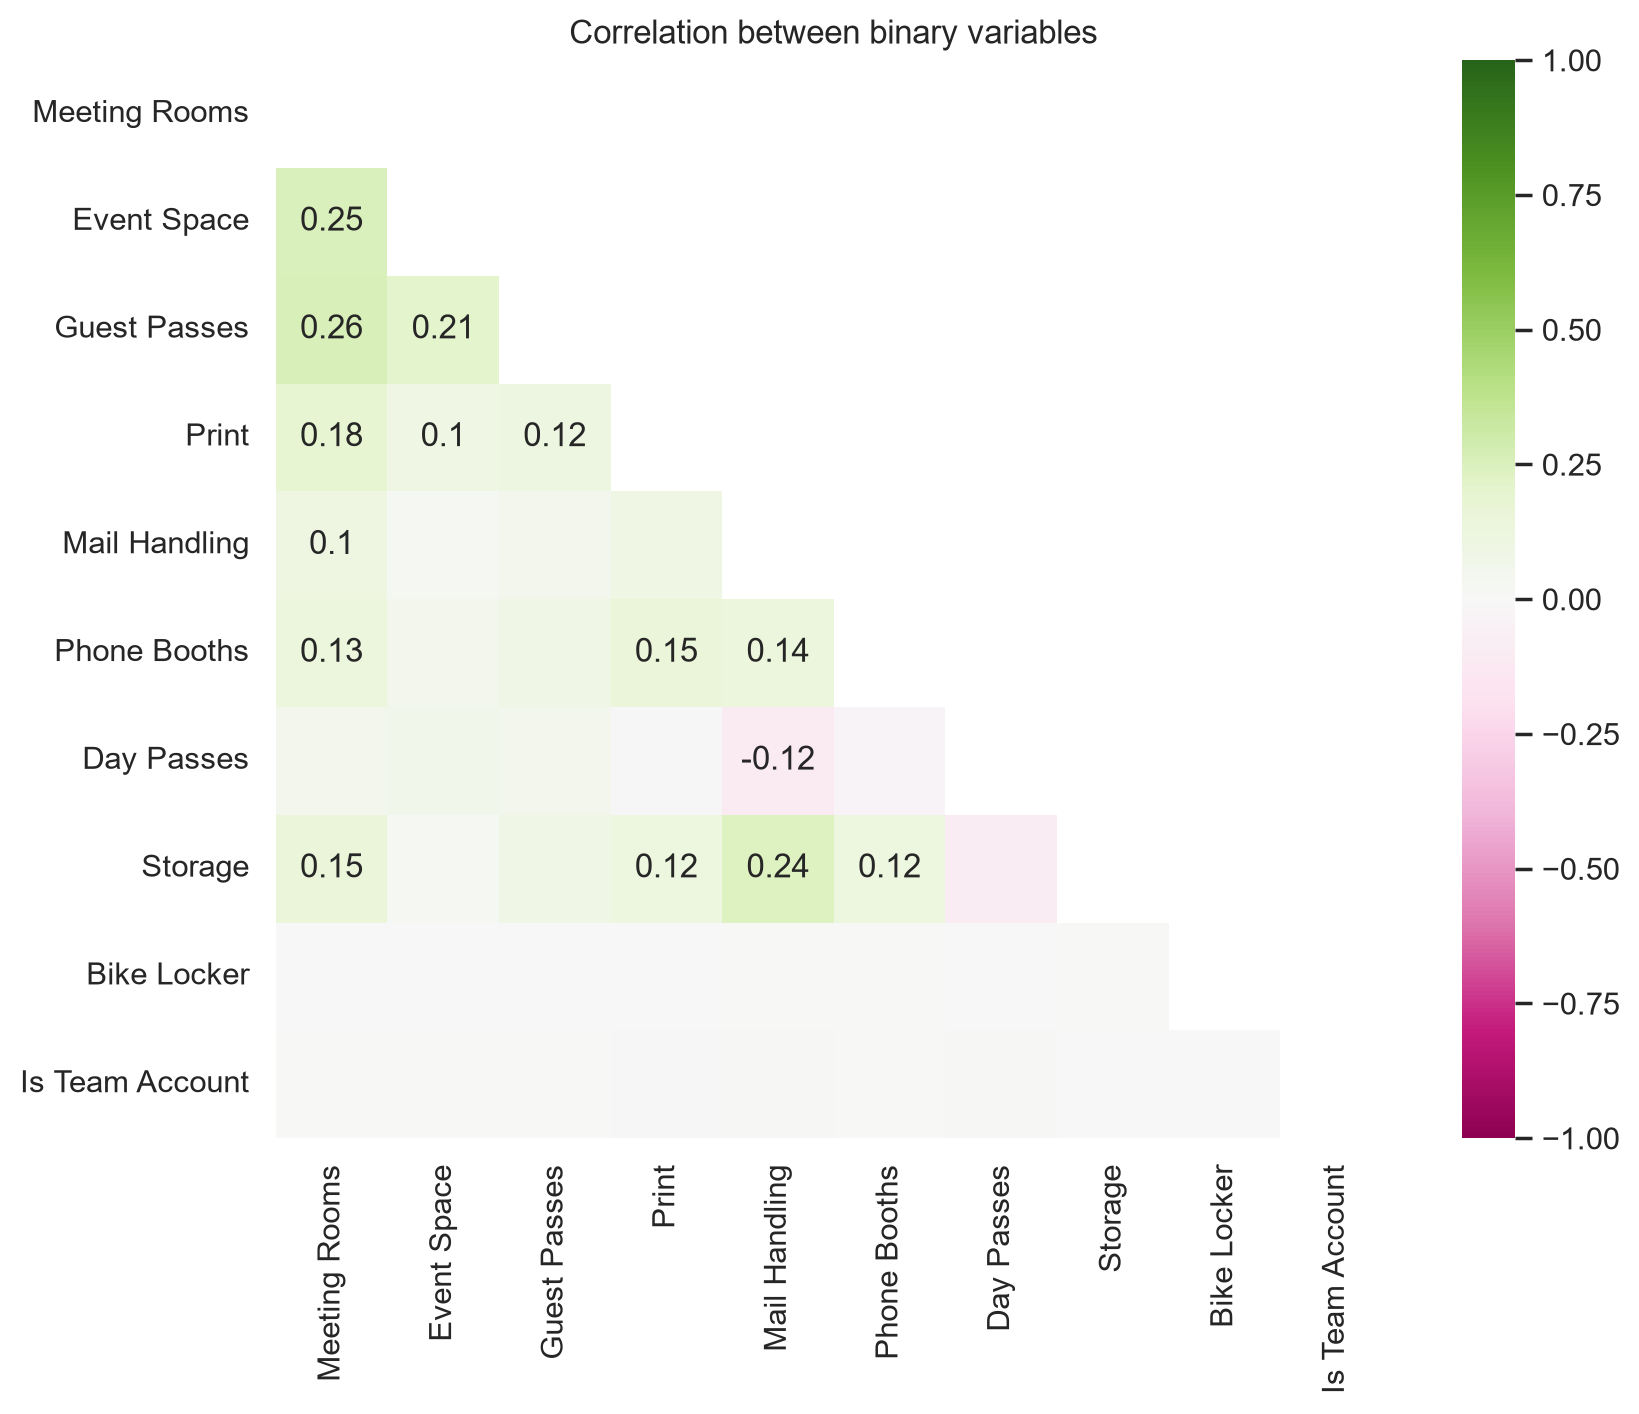

In [32]:
binary_all = binary_vars + ["is_team_account"]   # opcional: inclui is_team_account

corr_bin = df[binary_all].astype(int).corr()
corr_bin.index = corr_bin.columns = corr_bin.columns.str.replace("uses_", "").str.replace("_", " ").str.title()

annot = corr_bin.round(2).astype(str)
annot = annot.where(corr_bin.abs() >= 0.1, "")   # esconde |valor| < 0.1

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_bin, dtype=bool))
sns.heatmap(corr_bin, mask=mask, annot=annot, fmt="", cmap="PiYG", vmin=-1, vmax=1, center=0)
plt.title("Correlation between binary variables")
plt.show()

Note that correlations below 0.1 in absolute value are not displayed.

Correlations between the binary variables are generally weak (most positive values between 0.10 and 0.26), suggesting only a slight tendency for customers who use one service to also use others. The strongest links are between `meeting_rooms` and `guest_passes`/`event_space`, and between `mail_handling` and `storage`, but even these are modest. `day_passes` is the only service negatively related to others (e.g. `mail_handling`, -0.12), consistent with its higher use in cheaper tiers. `bike_locker` and `is_team_account` show no meaningful relationship with any service. 



#### Categorical variables vs. binary variables

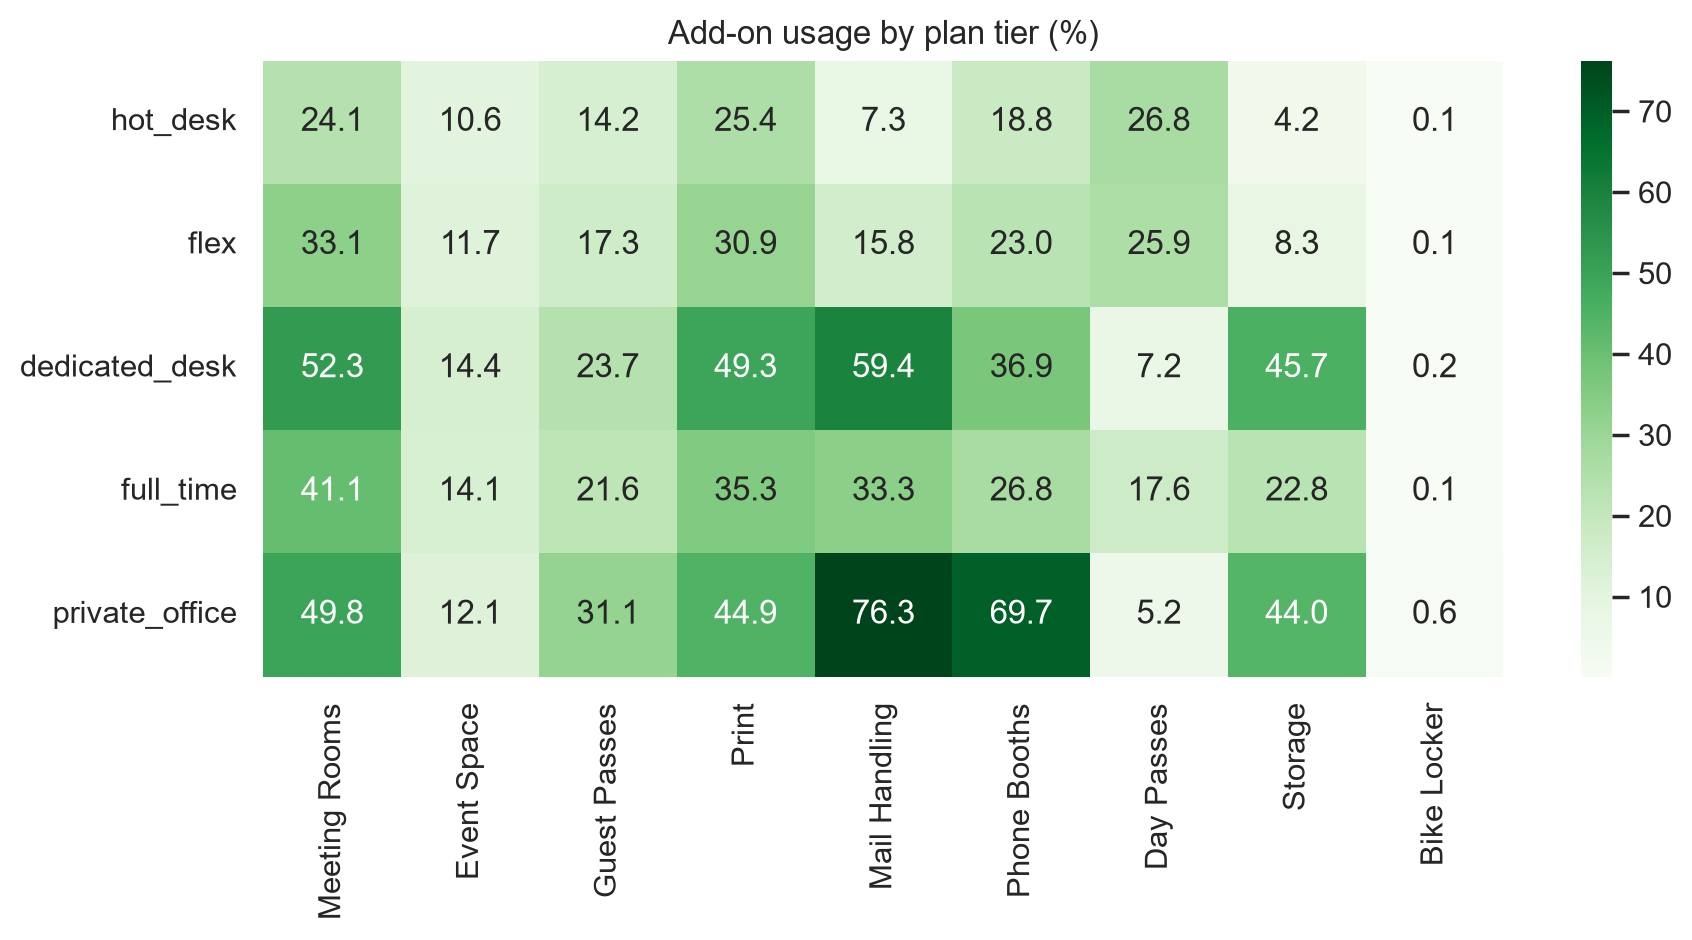

In [33]:
tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

usage_by_tier = df.groupby("plan_tier")[binary_vars].mean().loc[tier_order] * 100
usage_by_tier = usage_by_tier.astype(float)
usage_by_tier.columns = usage_by_tier.columns.str.replace("uses_", "").str.replace("_", " ").str.title()

plt.figure(figsize=(10, 4))
sns.heatmap(usage_by_tier, annot=True, fmt=".1f", cmap="Greens")
plt.title("Add-on usage by plan tier (%)")
plt.ylabel("")
plt.show()

The heatmap shows that add-on usage **depends on the plan tier**, but not in a single direction:

- **Increases with tier:** `mail_handling`, `phone_booths` and `storage` are far more common in the higher tiers. For example, `mail_handling` goes from 7.3% in `hot_desk` to 76.3% in `private_office`, and `storage` from 4.2% to 44.0%.
- **Decreases with tier:** `day_passes` are most used in `hot_desk` (26.8%) and `flex` (25.9%) and almost unused in `private_office` (5.2%). This is plausible, since customers with less access to the space buy extra days.
- **Increases, but not monotonically:** `meeting_rooms`, `print` and `guest_passes` are generally higher in the more expensive tiers, but `dedicated_desk` stands out. For instance, it uses meeting rooms more (52.3%) than `full_time` (41.1%).
- **Little variation:** `event_space` stays between 10% and 14% in all tiers, and `bike_locker` is almost never used (below 1%).

These results partially support our initial hypothesis: cheaper tiers use fewer infrastructure services, but they rely more on day passes. This suggests that `plan_tier` is a useful variable to distinguish customer behaviour.

#### Numerical variables vs. Categorical variables

It is important to understand whether some services are associated with customers renewing more often. Additionally, this could be a sign that a service is particularly valuable and should be promoted more; or it could simply reflect that longer-tenured customers tend to require certain kinds of services.

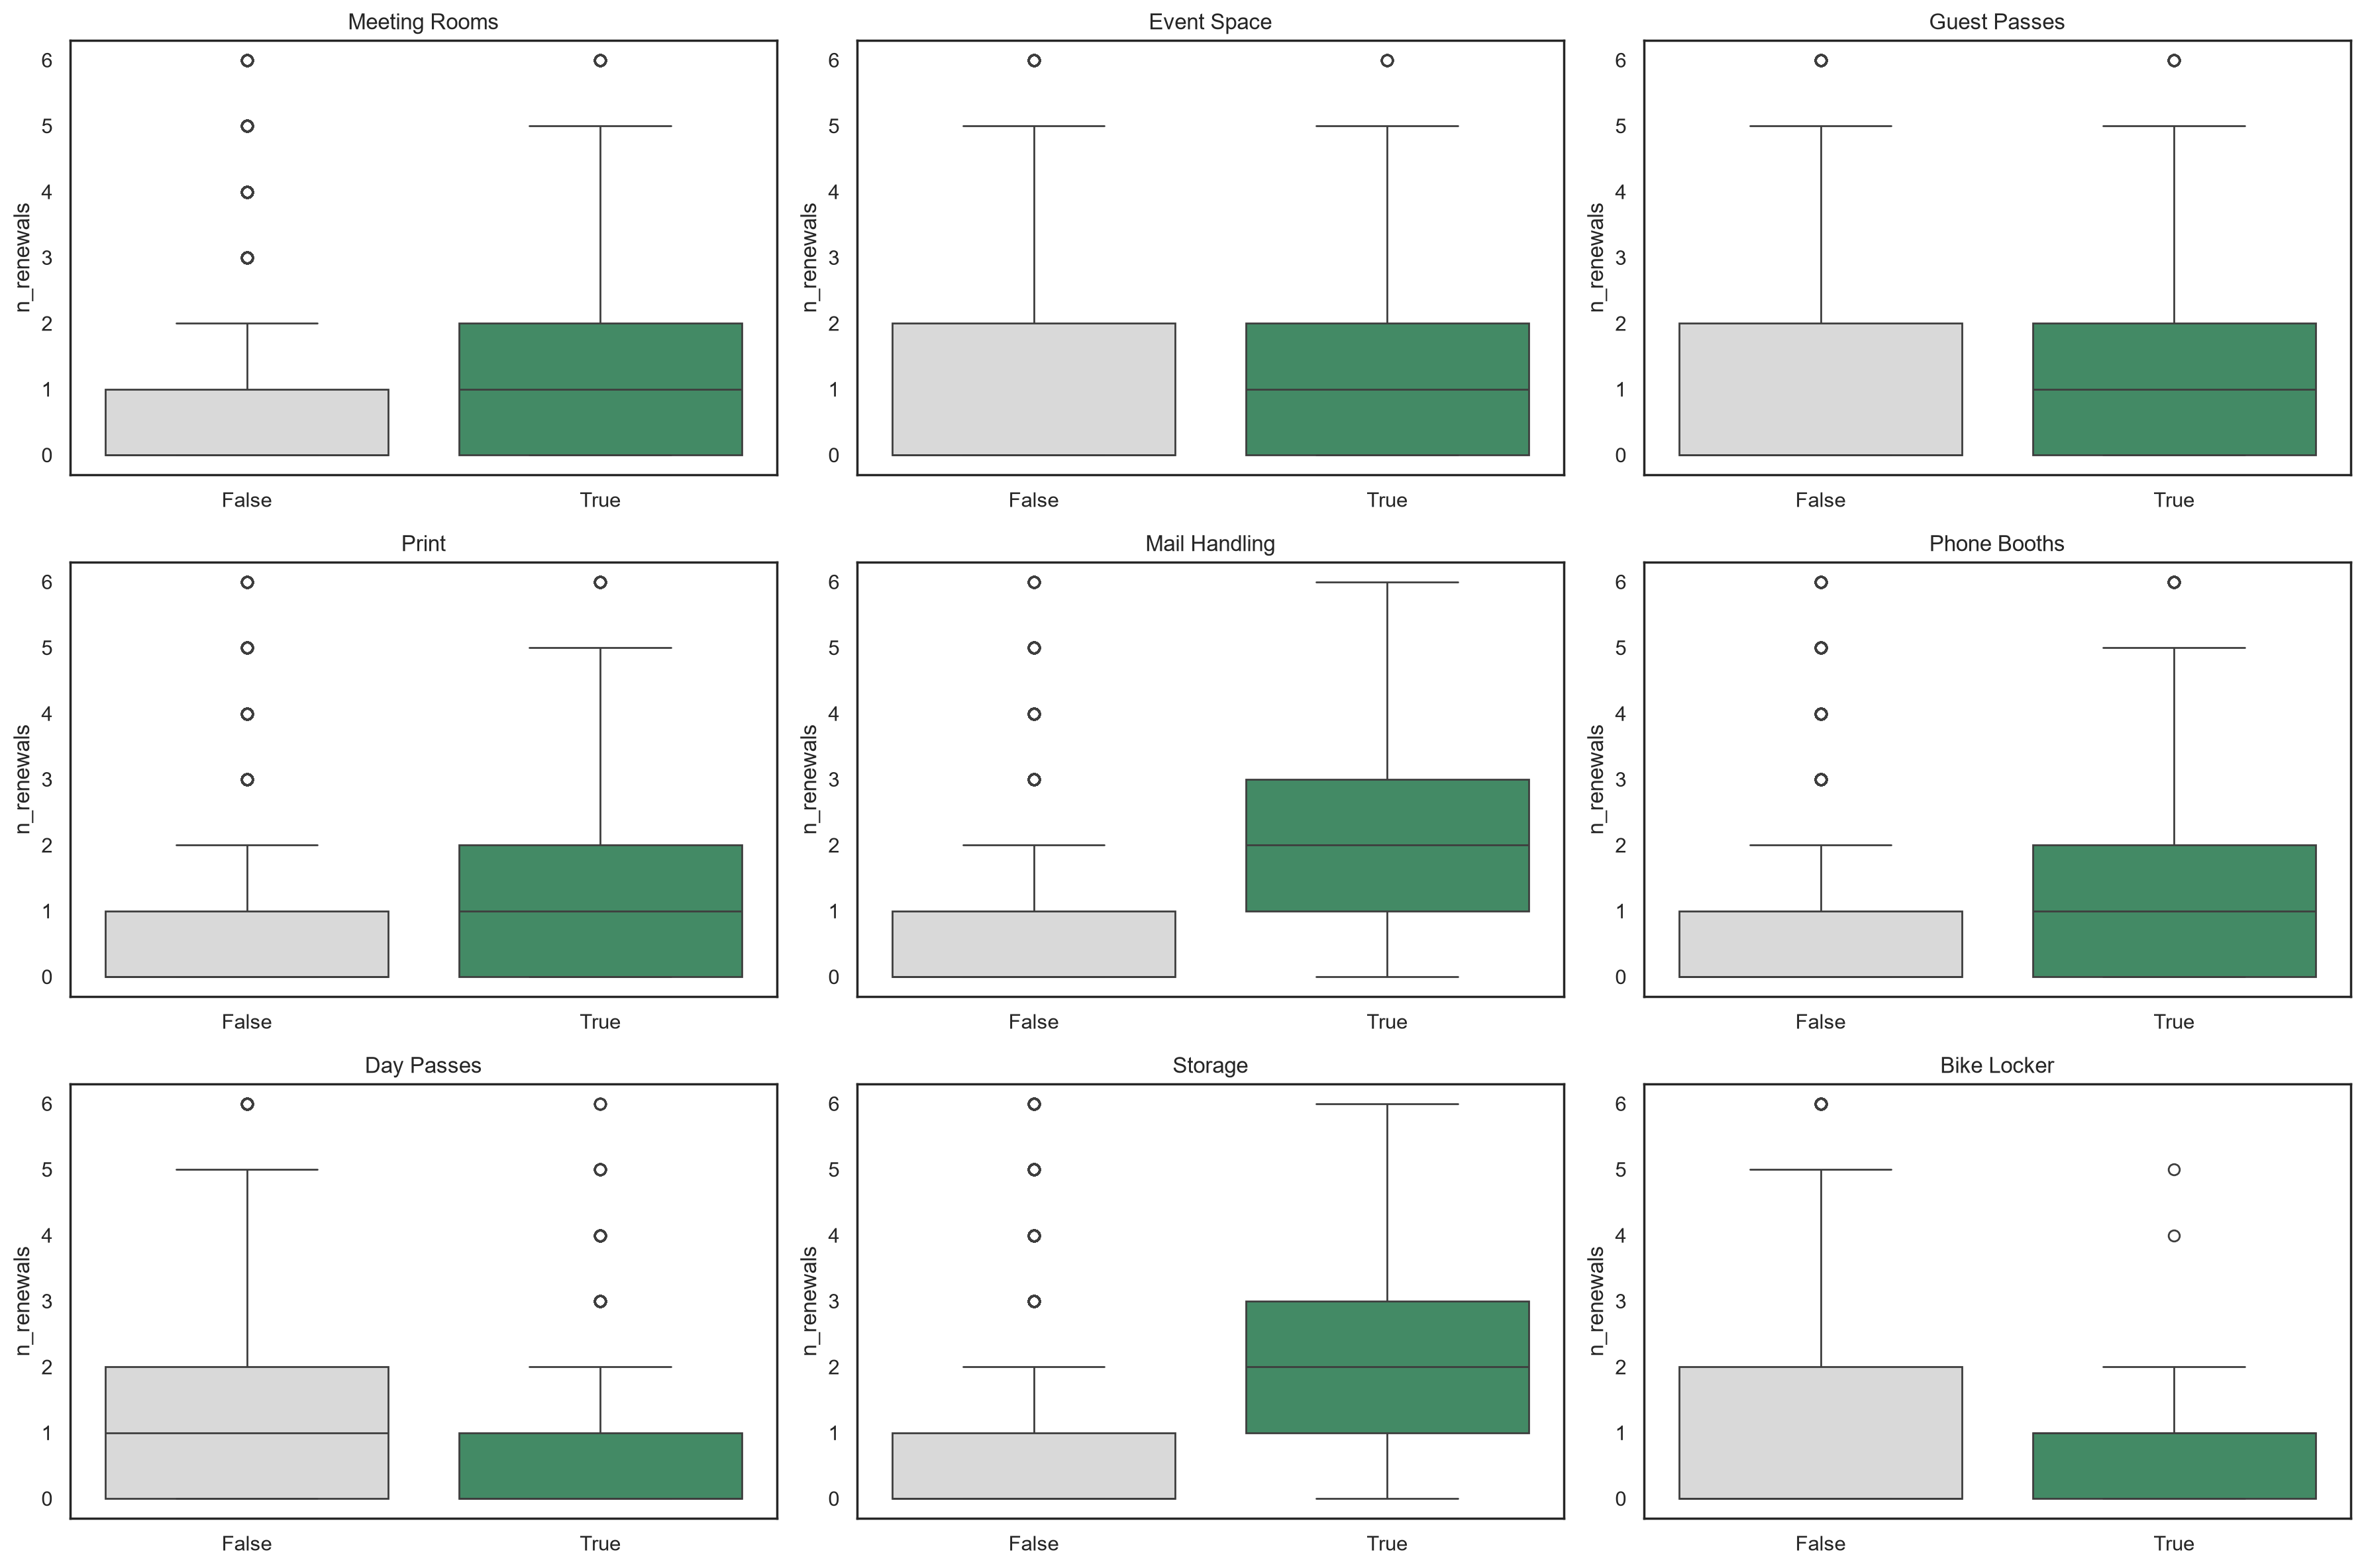

In [34]:
# The n_renewals column has negative values. For this analysis we decided to ignore them
df_plot = df[df["n_renewals"] >= 0]

bool_cols = [
    "uses_meeting_rooms", "uses_event_space", "uses_guest_passes",
    "uses_print", "uses_mail_handling", "uses_phone_booths",
    "uses_day_passes", "uses_storage", "uses_bike_locker"
]

# False = light grey, True = main color
palette = ["#D9D9D9", main_color]

fig, axes = plt.subplots(3, 3, figsize=(18, 12))

for ax, c in zip(axes.flatten(), bool_cols):
    sns.boxplot(data=df_plot, x=c, y="n_renewals", hue=c,
                palette=palette, legend=False, ax=ax)
    ax.set_title(c.replace("uses_", "").replace("_", " ").title())
    ax.set_xlabel("")

plt.tight_layout()

os.makedirs(os.path.join('..', 'figures', 'eda'), exist_ok=True)
plt.savefig(os.path.join('..', 'figures', 'eda', 'n_renewals_vs_bool_cols.png'), dpi=200)

plt.show()

Customers who use `mail_handling` and `storage` renew clearly more often (median of 2 renewals versus 0 for non-users). `phone_booths`, `print` and `meeting_rooms` show a moderate increase (about +0.5 renewals on average), while `guest_passes` and `event_space` show only a small one. 

`day_passes` is the only service associated with fewer renewals, which is consistent with its higher use in cheaper plans. This may also suggest that customers who buy extra days do not want to commit to a full monthly subscription. 

`bike_locker` has too few users (26) for any conclusion.

These are associations only: plan tier and membership length likely influence both service usage and renewals.

#### Date variables

In [35]:
df[["membership_start", "membership_end", "last_badge_swipe"]].describe()

,membership_start,membership_end,last_badge_swipe
count,15170,15170,15170
mean,2022-03-15 23:58:45.959129,2009-05-22 16:11:21.555702,2023-02-14 01:24:46.038233
min,2021-01-01 00:00:00,1970-01-01 00:00:00,2020-09-06 00:00:00
25%,2021-06-02 00:00:00,1970-01-01 00:00:00,2022-08-13 00:00:00
50%,2022-01-07 00:00:00,2022-08-22 00:00:00,2023-05-06 00:00:00
75%,2022-11-05 00:00:00,2023-06-10 00:00:00,2023-10-16 00:00:00
max,2023-12-30 00:00:00,2024-01-01 00:00:00,2024-04-28 00:00:00


In [36]:
df.shape

(15170, 30)

In [52]:
idx_invalid_1 = df.loc[df["membership_start"] > df["membership_end"]].index
idx_invalid_2 = df.loc[df["membership_start"] > df["last_badge_swipe"]].index
idx_invalid_3 = df.loc[df["membership_end"] < df["last_badge_swipe"]].index

print(f"""
Number of customers whose membership_start date comes after the membership_end date: {len(idx_invalid_1)}
Number of customers whose last_badge_swipe date comes before the membership_start date: {len(idx_invalid_2)}
Number of customers whose last_badge_swipe date comes after the membership_end date: {len(idx_invalid_3)}
""")


Number of customers whose membership_start date comes after the membership_end date: 4077
Number of customers whose last_badge_swipe date comes before the membership_start date: 128
Number of customers whose last_badge_swipe date comes after the membership_end date: 4195



In [39]:
(df["membership_end"]=="1970-01-01").sum()

np.int64(3885)

Most of the flagged rows are related to the "forced" `membership_end` date of 1970-01-01. Since this value appears 3885 times in our data, it is most likely a placeholder code for missing or unknown information, so we do not consider it when analysing this variable and its relationships with the others. 

Inconsistencies in the remaining dates still exist (once the placeholder is excluded) and should be addressed in a future section.

In [59]:
placeholder = pd.Timestamp("1970-01-01")
has_end = df["membership_end"] != placeholder   # note we are not modifying the df yet!

idx_invalid_1 = df.loc[has_end & (df["membership_start"] > df["membership_end"])].index # Condition 1
idx_invalid_2 = df.loc[df["membership_start"] > df["last_badge_swipe"]].index # Condition 2
idx_invalid_3 = df.loc[has_end & (df["membership_end"] < df["last_badge_swipe"])].index # Condition 3

inter_12 = idx_invalid_1.intersection(idx_invalid_2)
inter_23 = idx_invalid_2.intersection(idx_invalid_3)
inter_13 = idx_invalid_1.intersection(idx_invalid_3)
inter_123 = inter_12.intersection(idx_invalid_3)
union_all = idx_invalid_1.union(idx_invalid_2).union(idx_invalid_3)

print(f"""
Excluding membership_end = 1970-01-01:
Condition 1: {len(idx_invalid_1)} | Condition 2: {len(idx_invalid_2)} | Condition 3: {len(idx_invalid_3)}
1 & 2: {len(inter_12)} | 2 & 3: {len(inter_23)} | 1 & 3: {len(inter_13)} | all three: {len(inter_123)}
Total rows with at least one inconsistency: {len(union_all)}
""")


Excluding membership_end = 1970-01-01:
Condition 1: 192 | Condition 2: 128 | Condition 3: 310
1 & 2: 17 | 2 & 3: 8 | 1 & 3: 183 | all three: 8
Total rows with at least one inconsistency: 430



After ignoring the `membership_end = 1970-01-01` placeholder, only a small number of date inconsistencies remain: 430 customers (about 2.8% of the dataset) have at least one. 

The conditions "`membership_start` after `membership_end`" and "`last_badge_swipe` after `membership_end`" overlap heavily (183 customers), suggesting that in most of these cases the `membership_end` date itself is the problem. These rows will be handled in the next section.

For now, we take a look at the *dates* themselves: how do the number of customers joining, leaving and showing up for the last time evolve over time, and is there a particular season in which customers tend to join or leave the coworking space?

**Membership duration**

The previous chart shows *when* customers join and leave, but not *how long* they stay. To explore this, we compute the duration of each membership (in days) as the difference between `membership_end` and `membership_start`. 

This analysis only includes customers who have already left (i.e. with a valid `membership_end`) and consistent dates, so durations are likely underestimated, since long-standing customers who are still active are not represented.

Customers analysed: 11093 of 15170
count    11093.0
mean       329.0
std        289.0
min          1.0
25%         69.0
50%        252.0
75%        536.0
max       1095.0
Name: tenure_days, dtype: float64


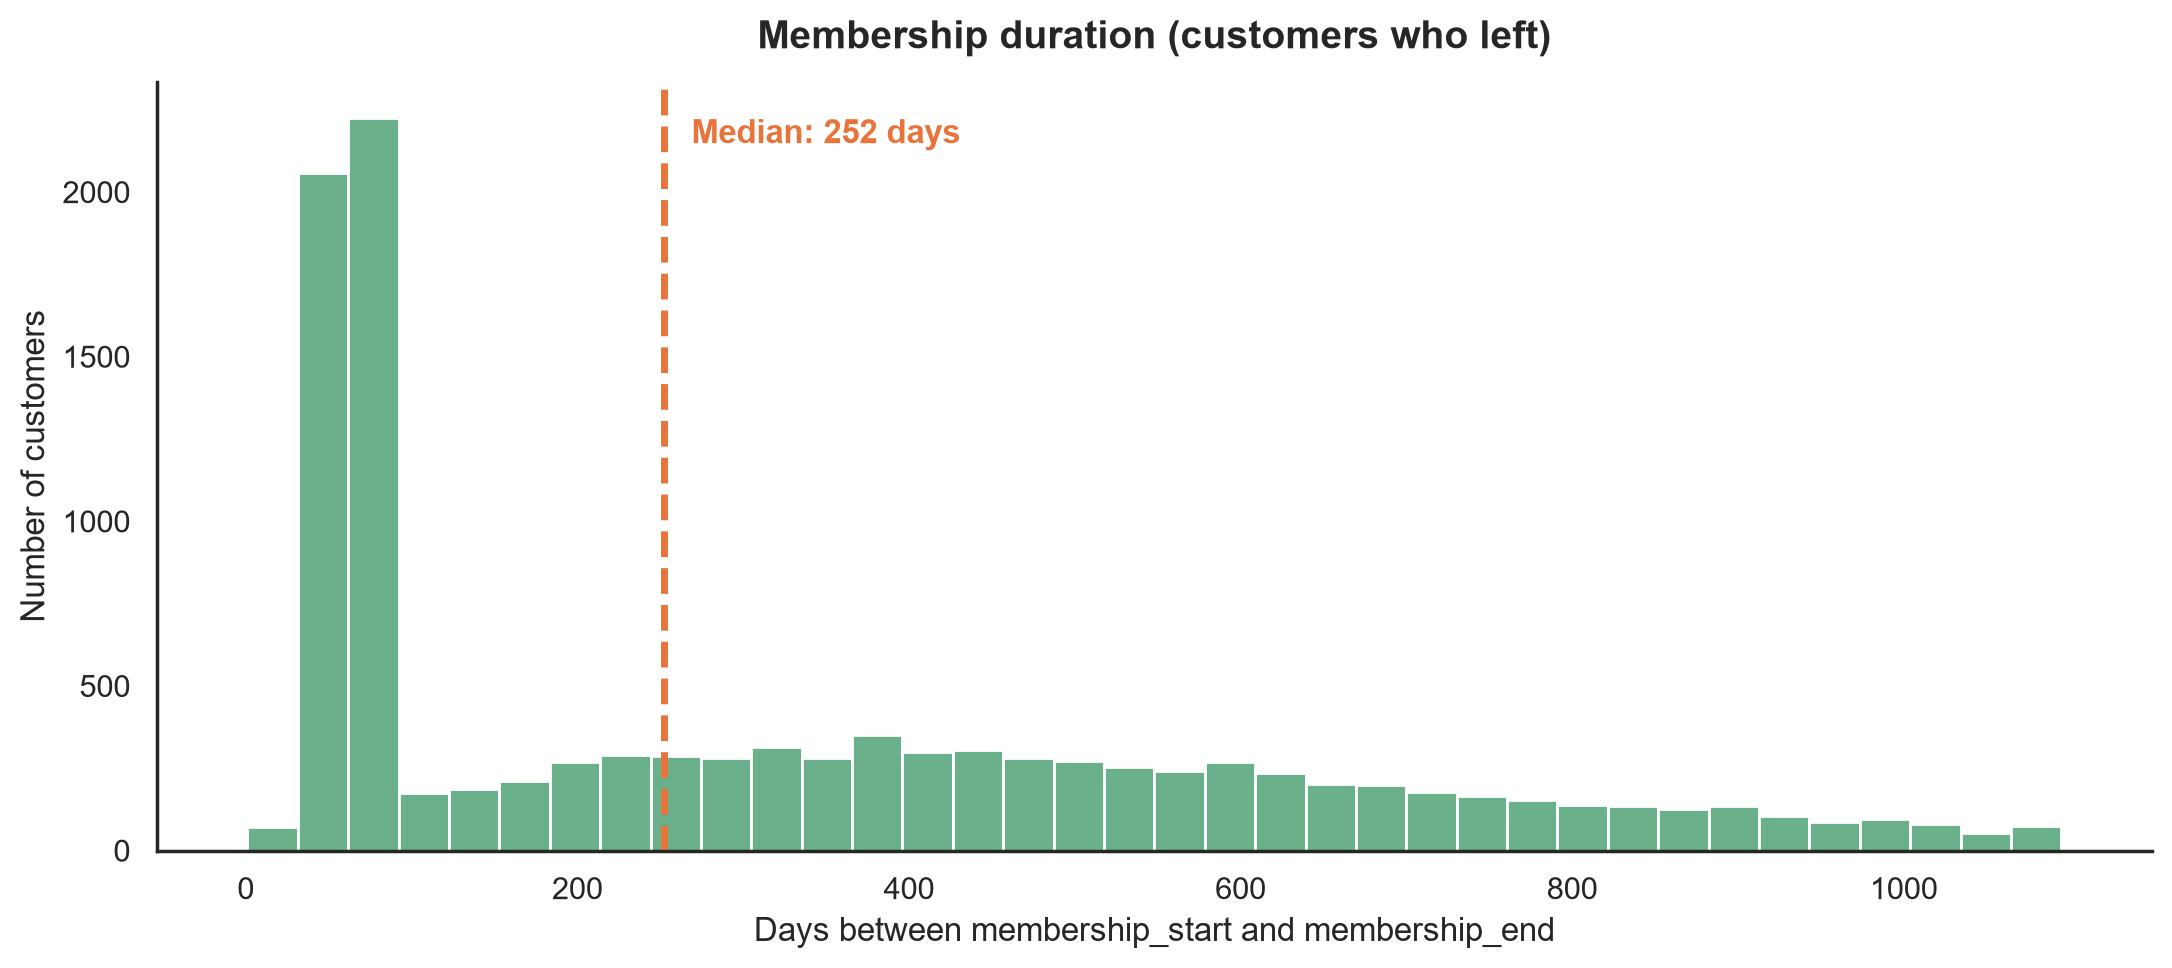

In [66]:
placeholder = pd.Timestamp("1970-01-01")

# só clientes que saíram (sem placeholder) e com datas coerentes
df_tenure = df.loc[
    (df["membership_end"] != placeholder) &
    (df["membership_end"] >= df["membership_start"])
].copy()

df_tenure["tenure_days"] = (df_tenure["membership_end"] - df_tenure["membership_start"]).dt.days

print(f"Customers analysed: {len(df_tenure)} of {len(df)}")
print(df_tenure["tenure_days"].describe().round(0))

fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(df_tenure["tenure_days"], bins=36, color=main_color, edgecolor="white", ax=ax)

median = df_tenure["tenure_days"].median()
ax.axvline(median, color="#E8743B", linewidth=2.5, linestyle="--")
ax.annotate(f"Median: {median:.0f} days", xy=(median, ax.get_ylim()[1] * 0.92),
            xytext=(10, 0), textcoords="offset points", color="#E8743B", fontweight="bold")

ax.set_title("Membership duration (customers who left)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Days between membership_start and membership_end")
ax.set_ylabel("Number of customers")
sns.despine()
plt.tight_layout()
plt.show()

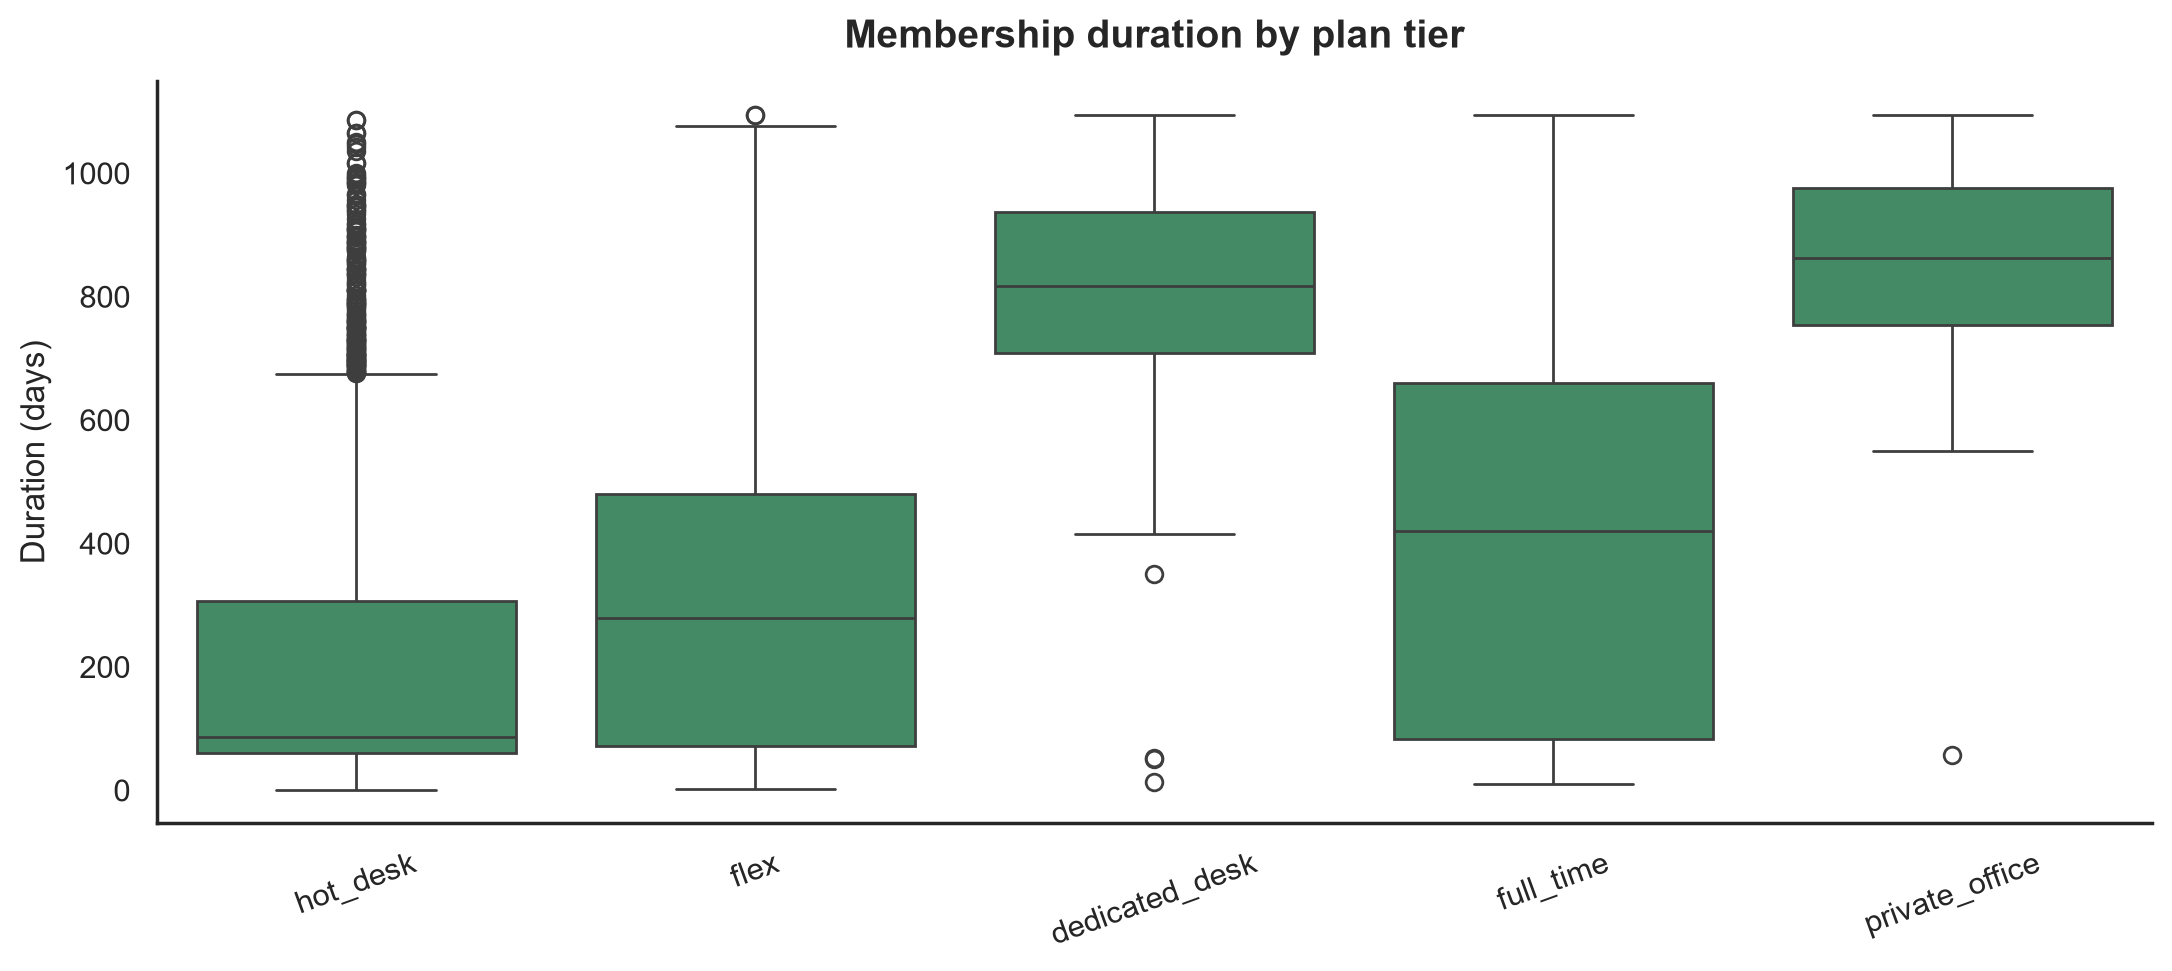

,count,mean,std,min,25%,50%,75%,max
plan_tier,,,,,,,,
hot_desk,4361.0,202.0,208.0,1.0,60.0,87.0,306.0,1087.0
flex,4207.0,303.0,235.0,2.0,72.0,279.0,480.0,1095.0
dedicated_desk,649.0,818.0,152.0,13.0,708.0,817.0,938.0,1095.0
full_time,1476.0,425.0,302.0,11.0,83.0,420.0,660.0,1095.0
private_office,347.0,856.0,151.0,57.0,754.0,863.0,976.0,1095.0


In [67]:
tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df_tenure, x="plan_tier", y="tenure_days", order=tier_order,
            color=main_color, ax=ax)

ax.set_title("Membership duration by plan tier", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Duration (days)")
ax.tick_params(axis="x", rotation=20)
sns.despine()
plt.tight_layout()
plt.show()

df_tenure.groupby("plan_tier")["tenure_days"].describe().loc[tier_order].round(0)

`dedicated_desk` and `private_office` are the plans with the longest-lasting customers (median duration of about 817 and 863 days, respectively), while `full_time` is the most heterogeneous plan, with durations spread widely (IQR from 83 to 660 days), possibly reflecting a group of customers who leave quickly alongside a larger group who stay much longer.

`hot_desk` has the shortest durations, with a strongly right-skewed distribution: half of the customers who left did so within 87 days, far below the median of `flex` (279 days), despite both plans having a similar number of customers who left (4,361 vs. 4,207).

These durations only cover customers who already left, and cheaper plans have more recent starts, so absolute values are likely underestimated for them.

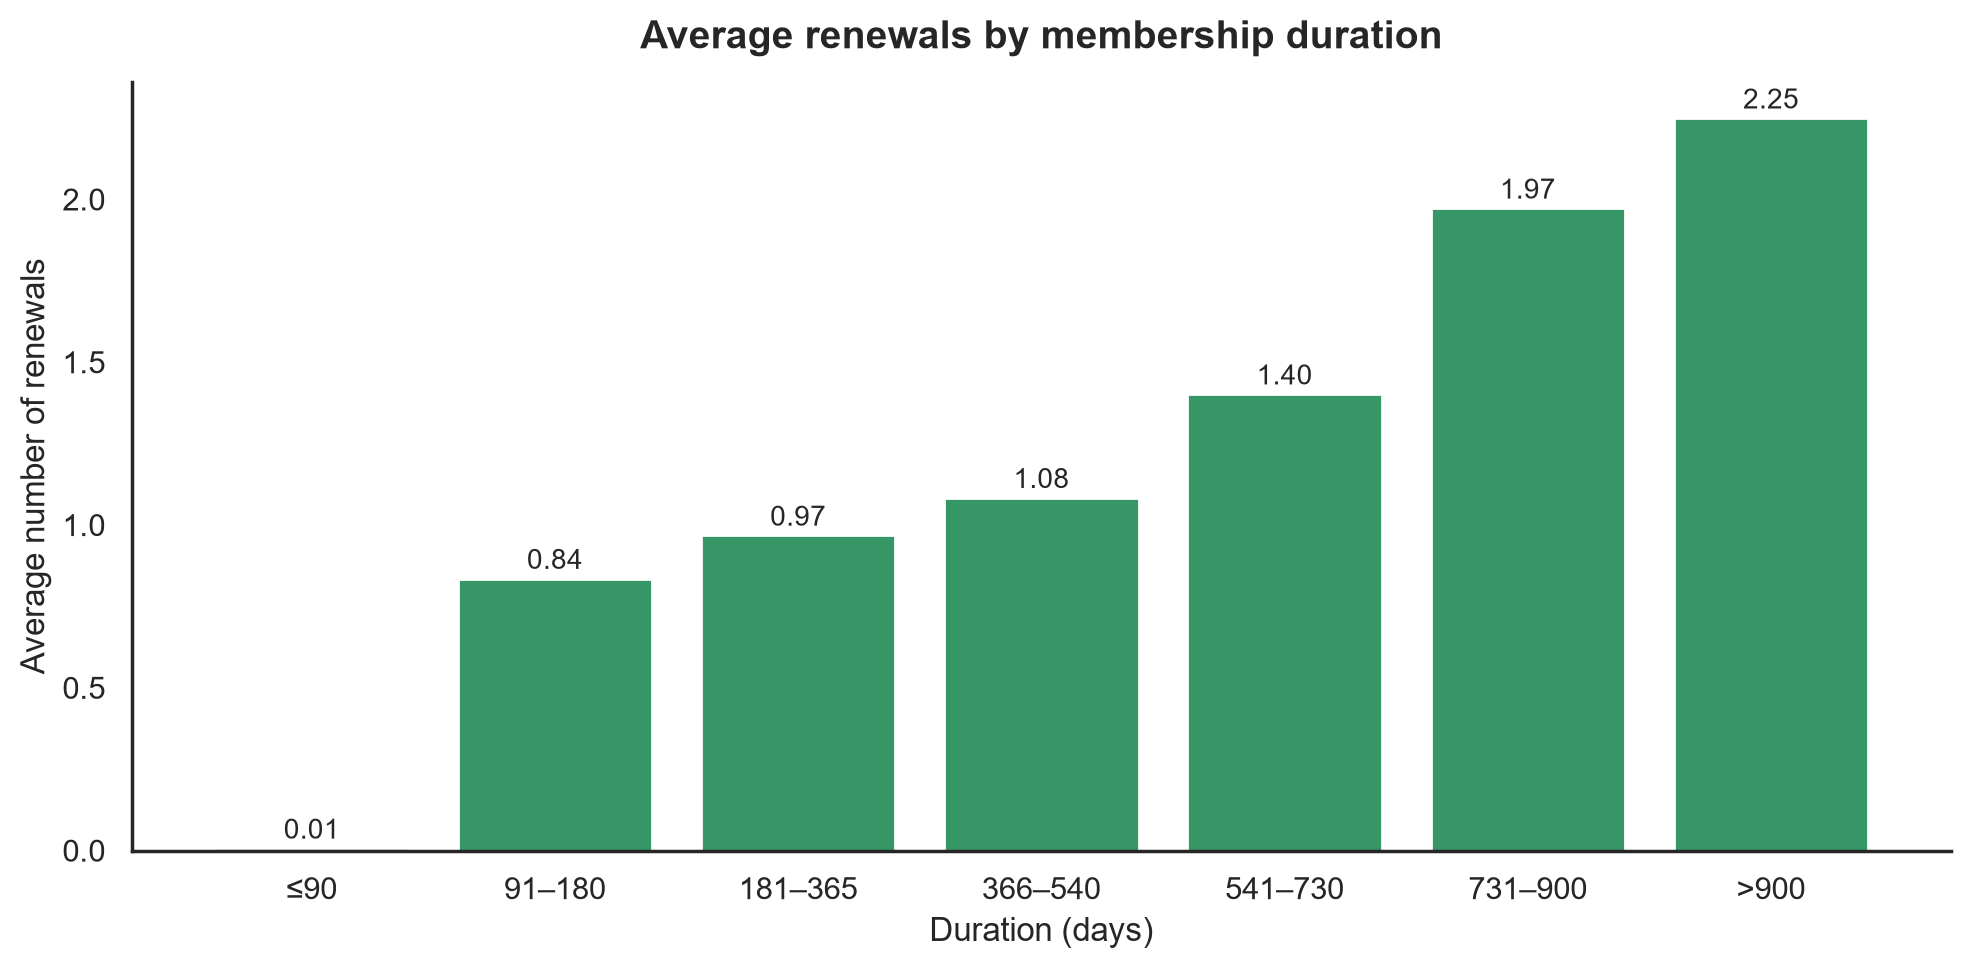

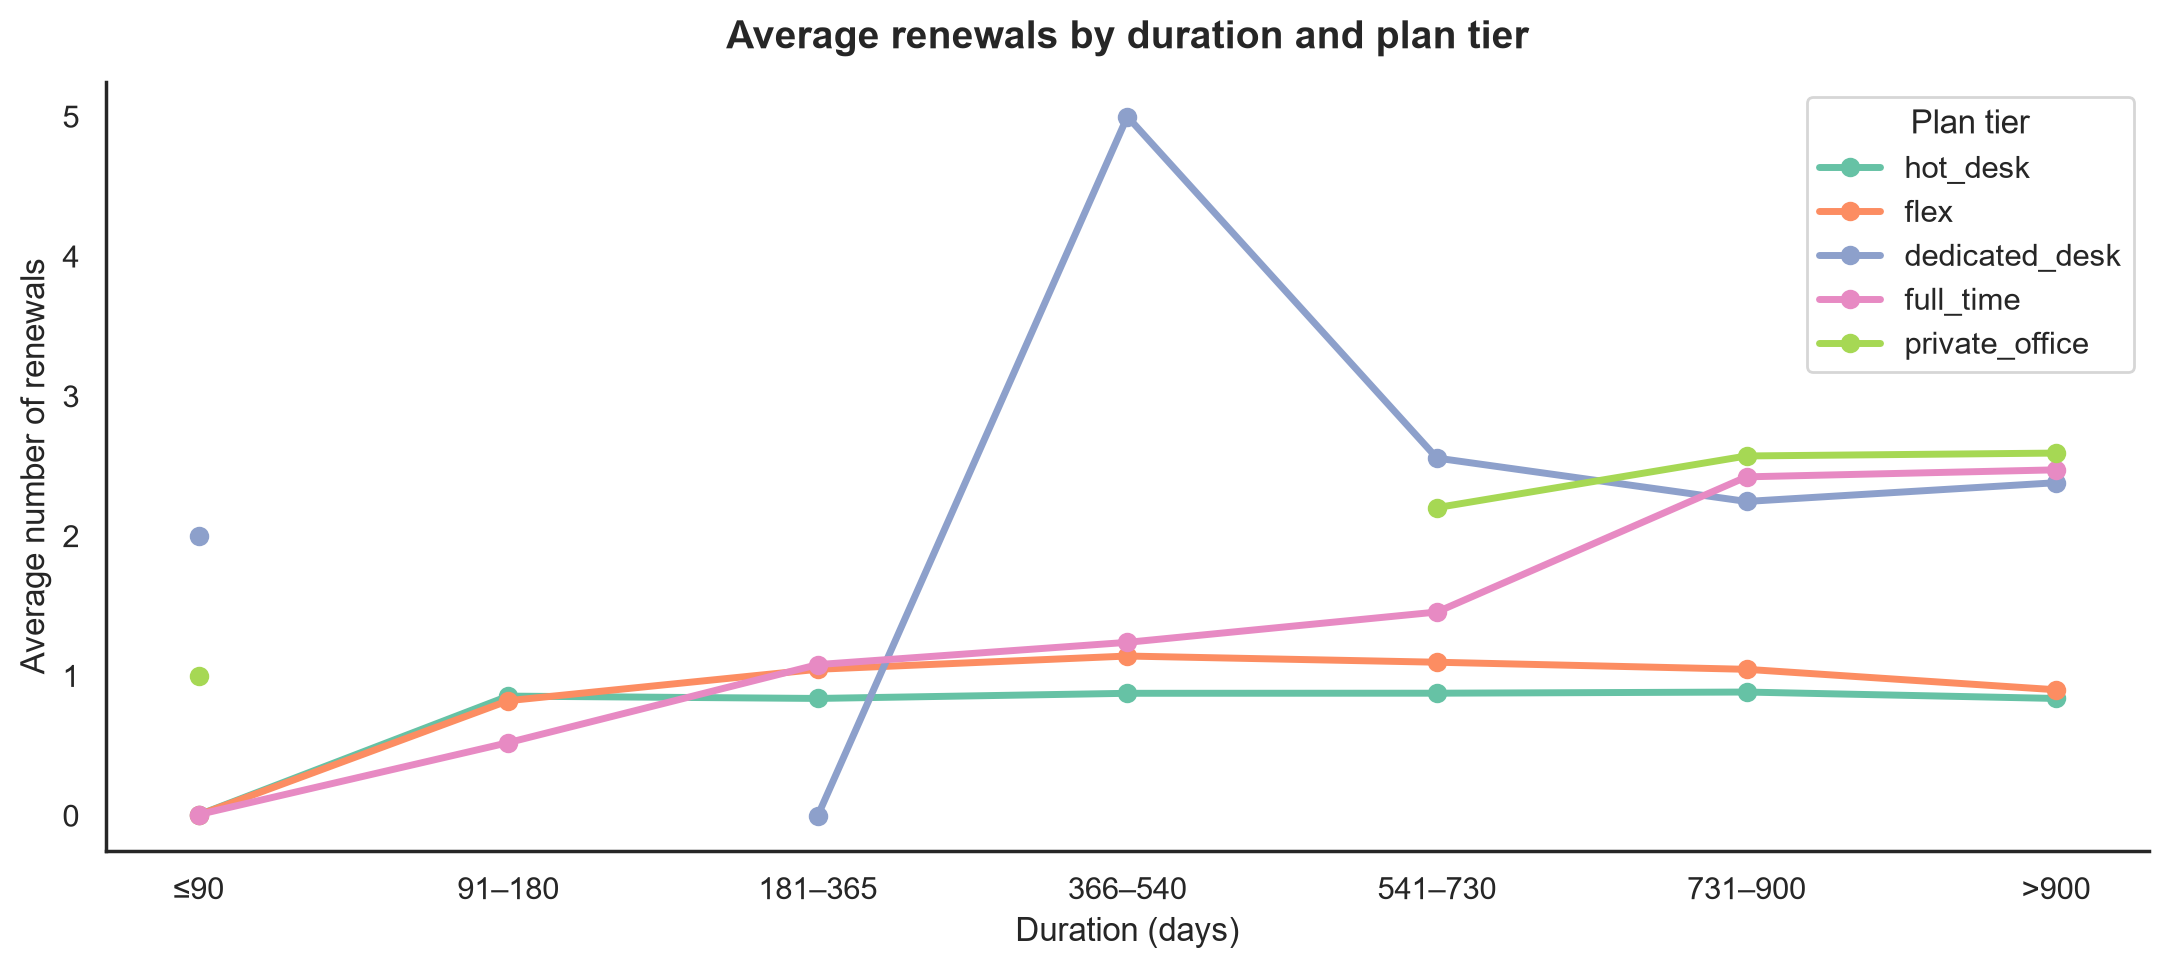

In [71]:
# df_tenure vem da célula anterior (clientes que saíram, datas coerentes)
df_ren = df_tenure[df_tenure["n_renewals"] >= 0].copy()

df_ren["tenure_bin"] = pd.cut(
    df_ren["tenure_days"],
    bins=[0, 90, 180, 365, 540, 730, 900, 1100],
    labels=["≤90", "91–180", "181–365", "366–540", "541–730", "731–900", ">900"]
)

# 1) média de renovações por faixa de duração
mean_by_bin = df_ren.groupby("tenure_bin", observed=True)["n_renewals"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(mean_by_bin.index.astype(str), mean_by_bin.values, color=main_color)
for i, v in enumerate(mean_by_bin.values):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=10)
ax.set_title("Average renewals by membership duration", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Duration (days)")
ax.set_ylabel("Average number of renewals")
sns.despine()
plt.tight_layout()
plt.show()

# 2) o mesmo, por plano
tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]
by_tier = (df_ren.groupby(["tenure_bin", "plan_tier"], observed=True)["n_renewals"]
           .mean().unstack()[tier_order])

fig, ax = plt.subplots(figsize=(11, 5))
by_tier.plot(ax=ax, marker="o", linewidth=2.5,
             color=sns.color_palette("Set2", len(tier_order)))
ax.set_title("Average renewals by duration and plan tier", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Duration (days)")
ax.set_ylabel("Average number of renewals")
ax.legend(title="Plan tier", frameon=True, fancybox=True)
sns.despine()
plt.tight_layout()
plt.show()

In [72]:
tbl = mean_tbl.where(count_tbl >= min_n).round(2)
tbl.index = tier_names
tbl.columns = [str(c) for c in tbl.columns]

tbl

,≤90,91–180,181–365,366–540,541–730,731–900,>900
Hot desk,0.00,0.85,0.84,0.87,0.88,0.88,0.84
Flex,0.00,0.82,1.05,1.14,1.10,1.05,0.90
Dedicated desk,NaN,NaN,NaN,NaN,2.56,2.25,2.38
Full time,0.01,NaN,1.08,1.24,1.46,2.42,2.47
Private office,NaN,NaN,NaN,NaN,2.20,2.57,2.59


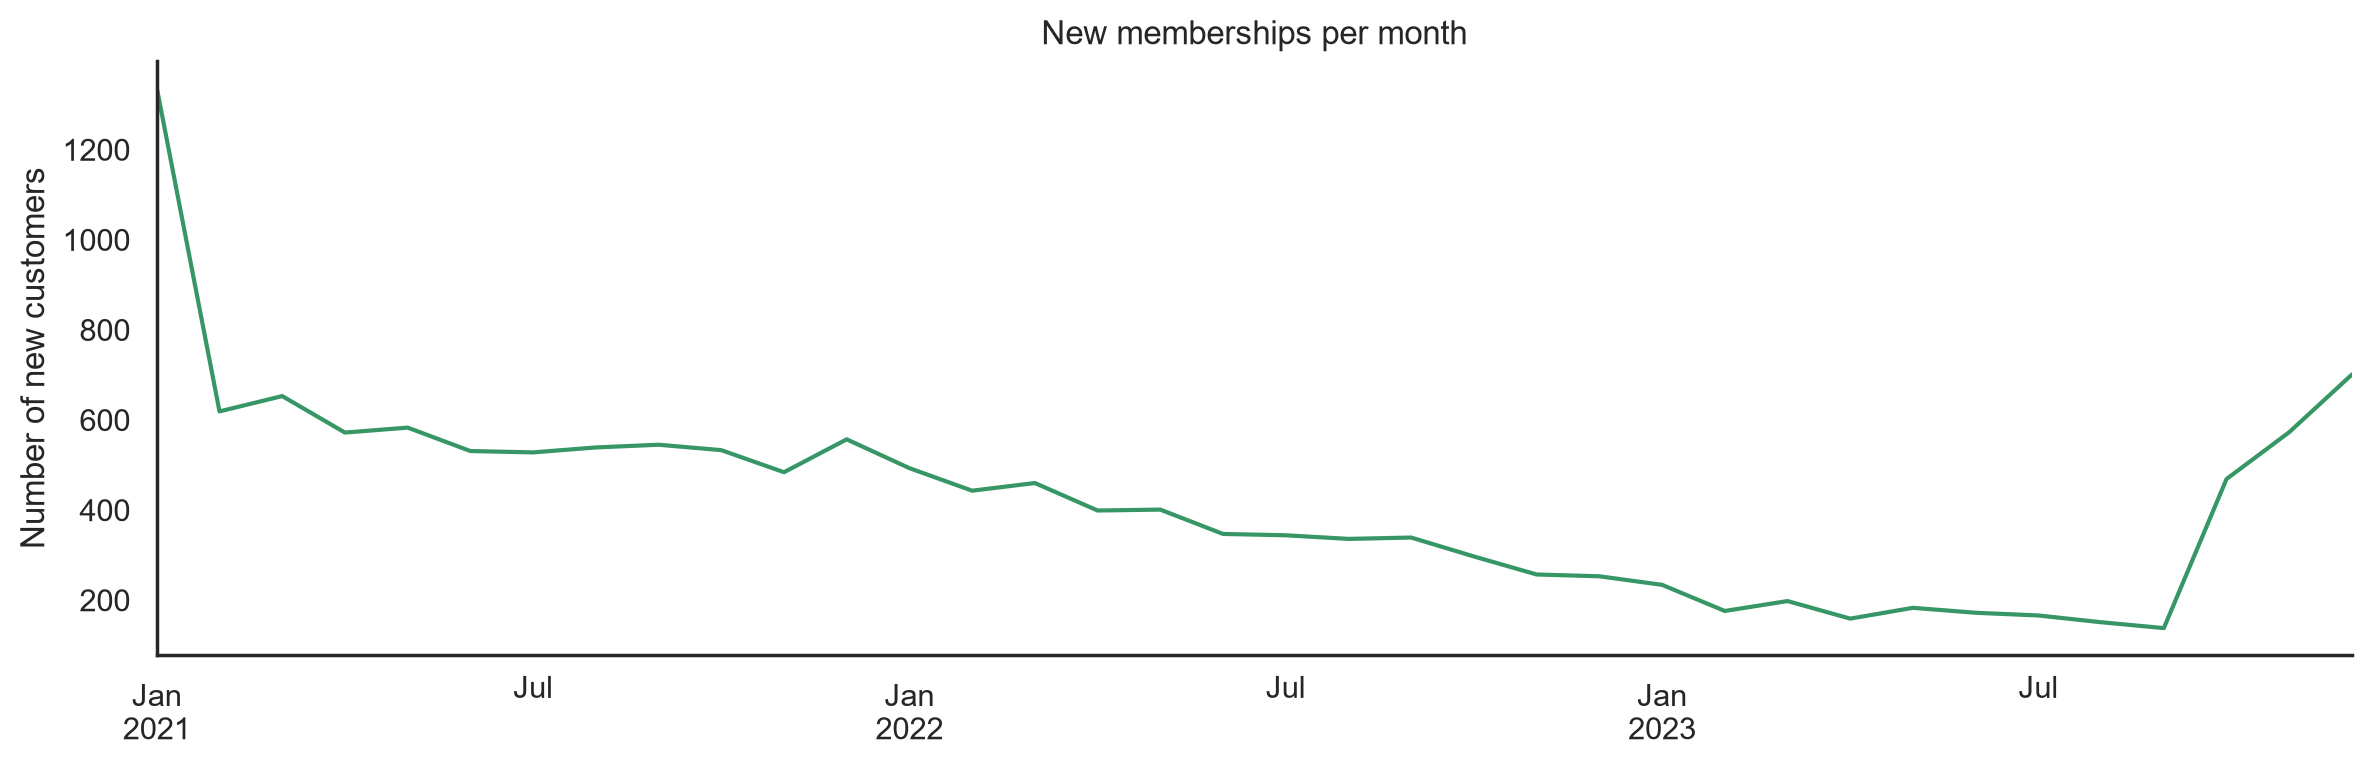

In [42]:
new_per_month = df.groupby(df["membership_start"].dt.to_period("M")).size()

plt.figure(figsize=(12, 4))
new_per_month.plot(color=main_color)
plt.title("New memberships per month")
plt.xlabel("")
plt.ylabel("Number of new customers")
sns.despine()
plt.tight_layout()
plt.show()

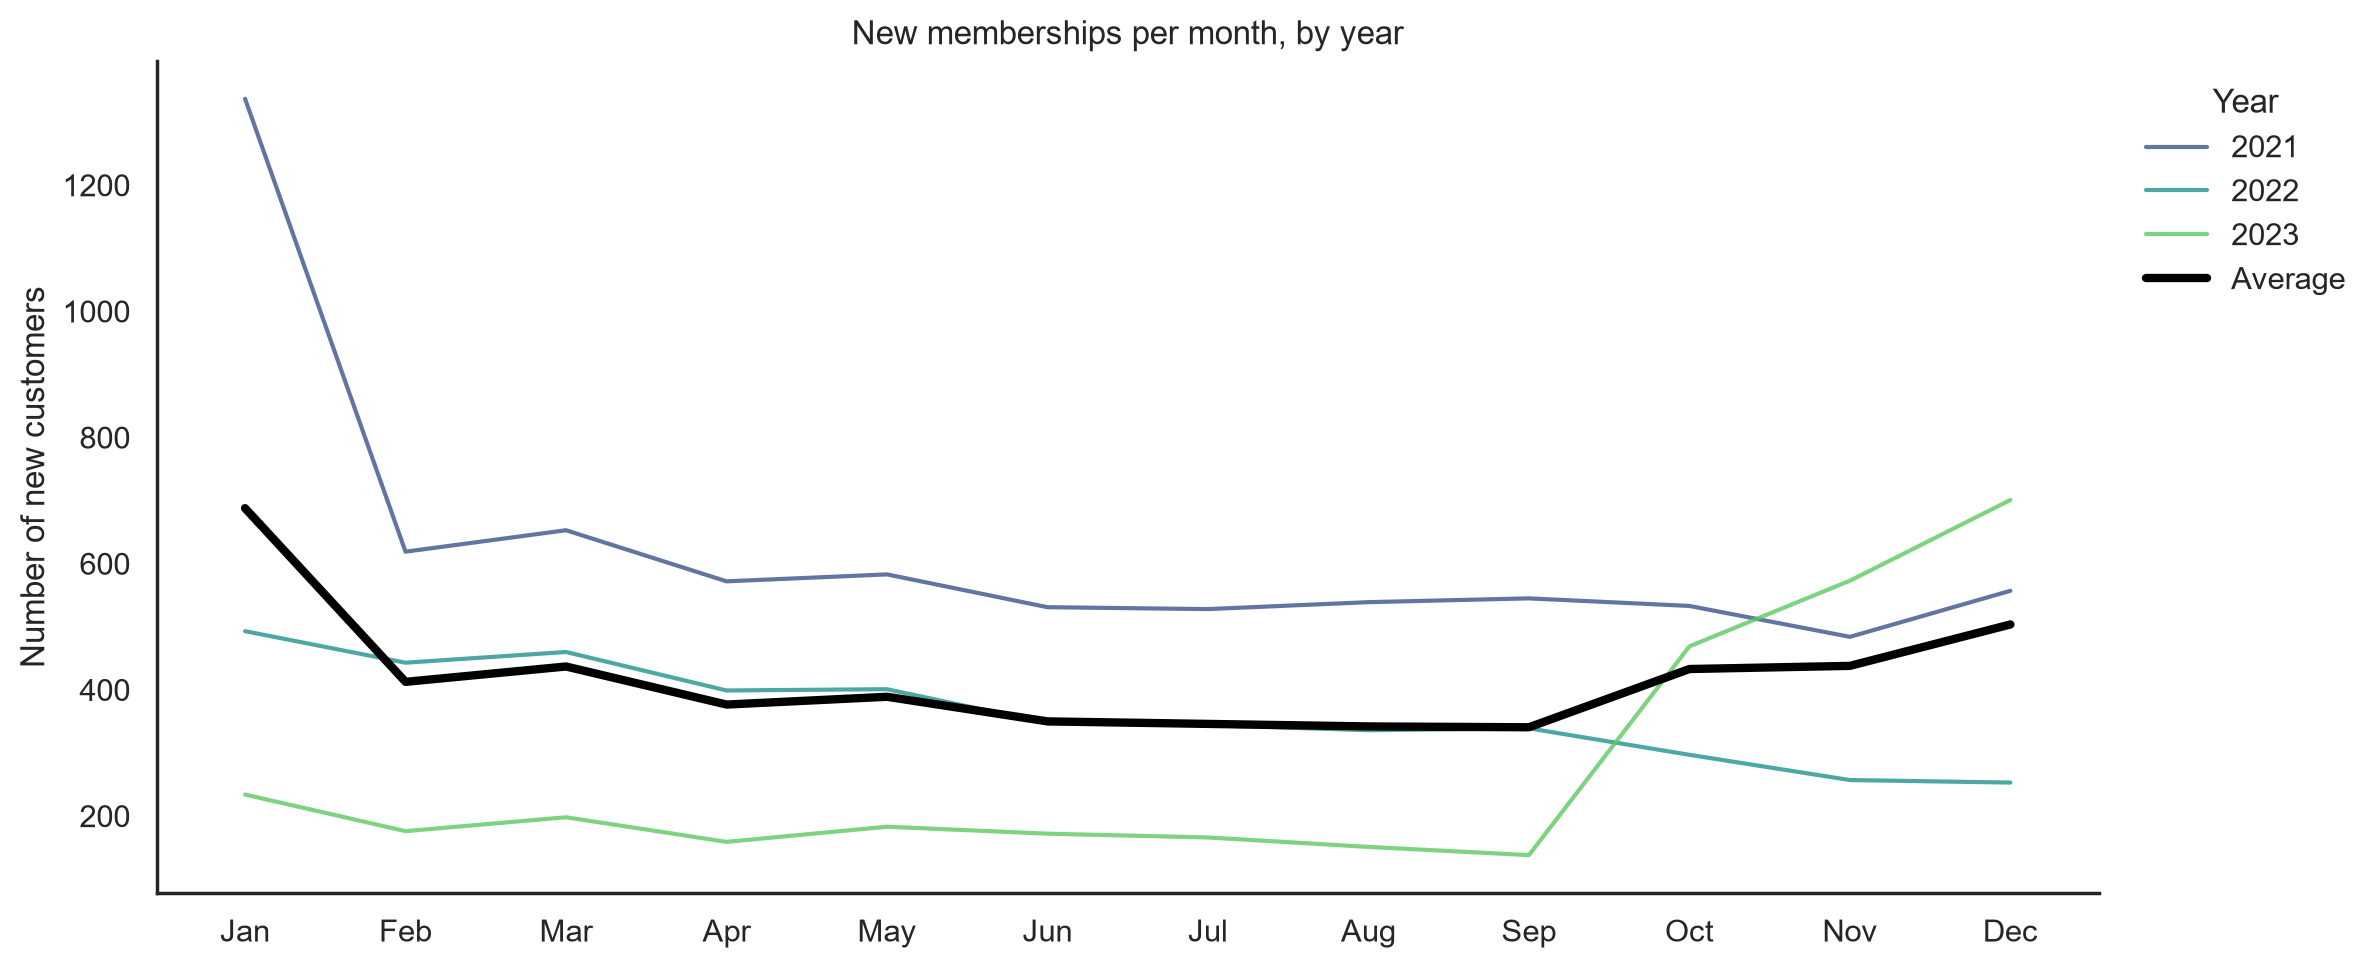

In [49]:
# nº de novos clientes por (ano, mês)
tmp = df.copy()
tmp["year"] = tmp["membership_start"].dt.year
tmp["month"] = tmp["membership_start"].dt.month

pivot = tmp.pivot_table(index="month", columns="year", values="membership_start", aggfunc="count")

fig, ax = plt.subplots(figsize=(12, 5))

# uma linha fininha por ano
colors_years = sns.color_palette("viridis", n_colors=pivot.shape[1])
for color, year in zip(colors_years, pivot.columns):
    ax.plot(pivot.index, pivot[year], color=color, alpha=0.8, label=str(year))

# média de todos os anos (a "tendência" sazonal)
ax.plot(pivot.index, pivot.mean(axis=1), color="black", linewidth=3, label="Average")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("New memberships per month, by year")
ax.set_xlabel("")
ax.set_ylabel("Number of new customers")
ax.legend(title="Year", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

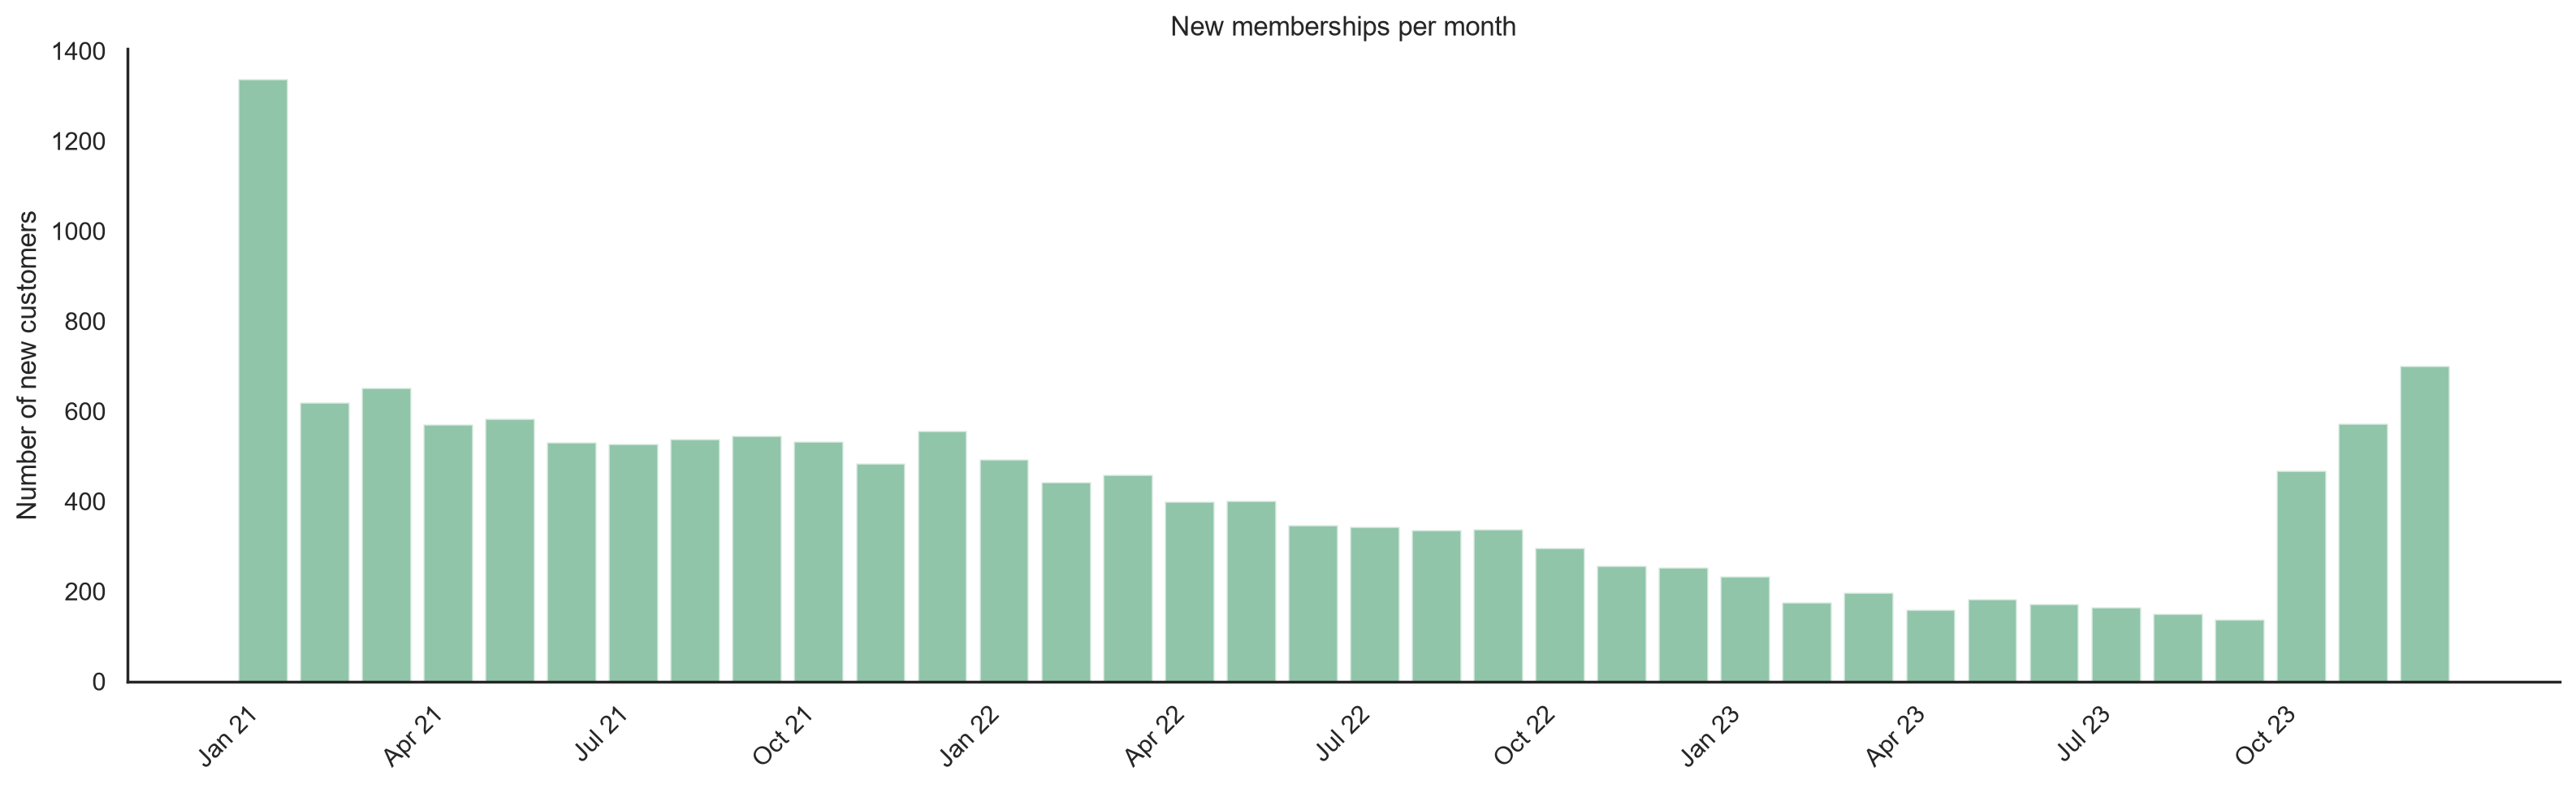

In [46]:
# nº de novos clientes por mês (inclui meses com 0)
monthly = df.set_index("membership_start").resample("MS").size()

# tendência suavizada (média móvel de 6 meses)
trend = monthly.rolling(6, center=True, min_periods=1).mean()

labels = monthly.index.strftime("%b %y")

fig, ax = plt.subplots(figsize=(16, 5))

ax.bar(range(len(monthly)), monthly.values, color=main_color, alpha=0.55, width=0.8)

step = 3
ax.set_xticks(range(0, len(monthly), step))
ax.set_xticklabels(labels[::step], rotation=45, ha="right")

ax.set_title("New memberships per month")
ax.set_xlabel("")
ax.set_ylabel("Number of new customers")
sns.despine()
plt.tight_layout()
plt.show()

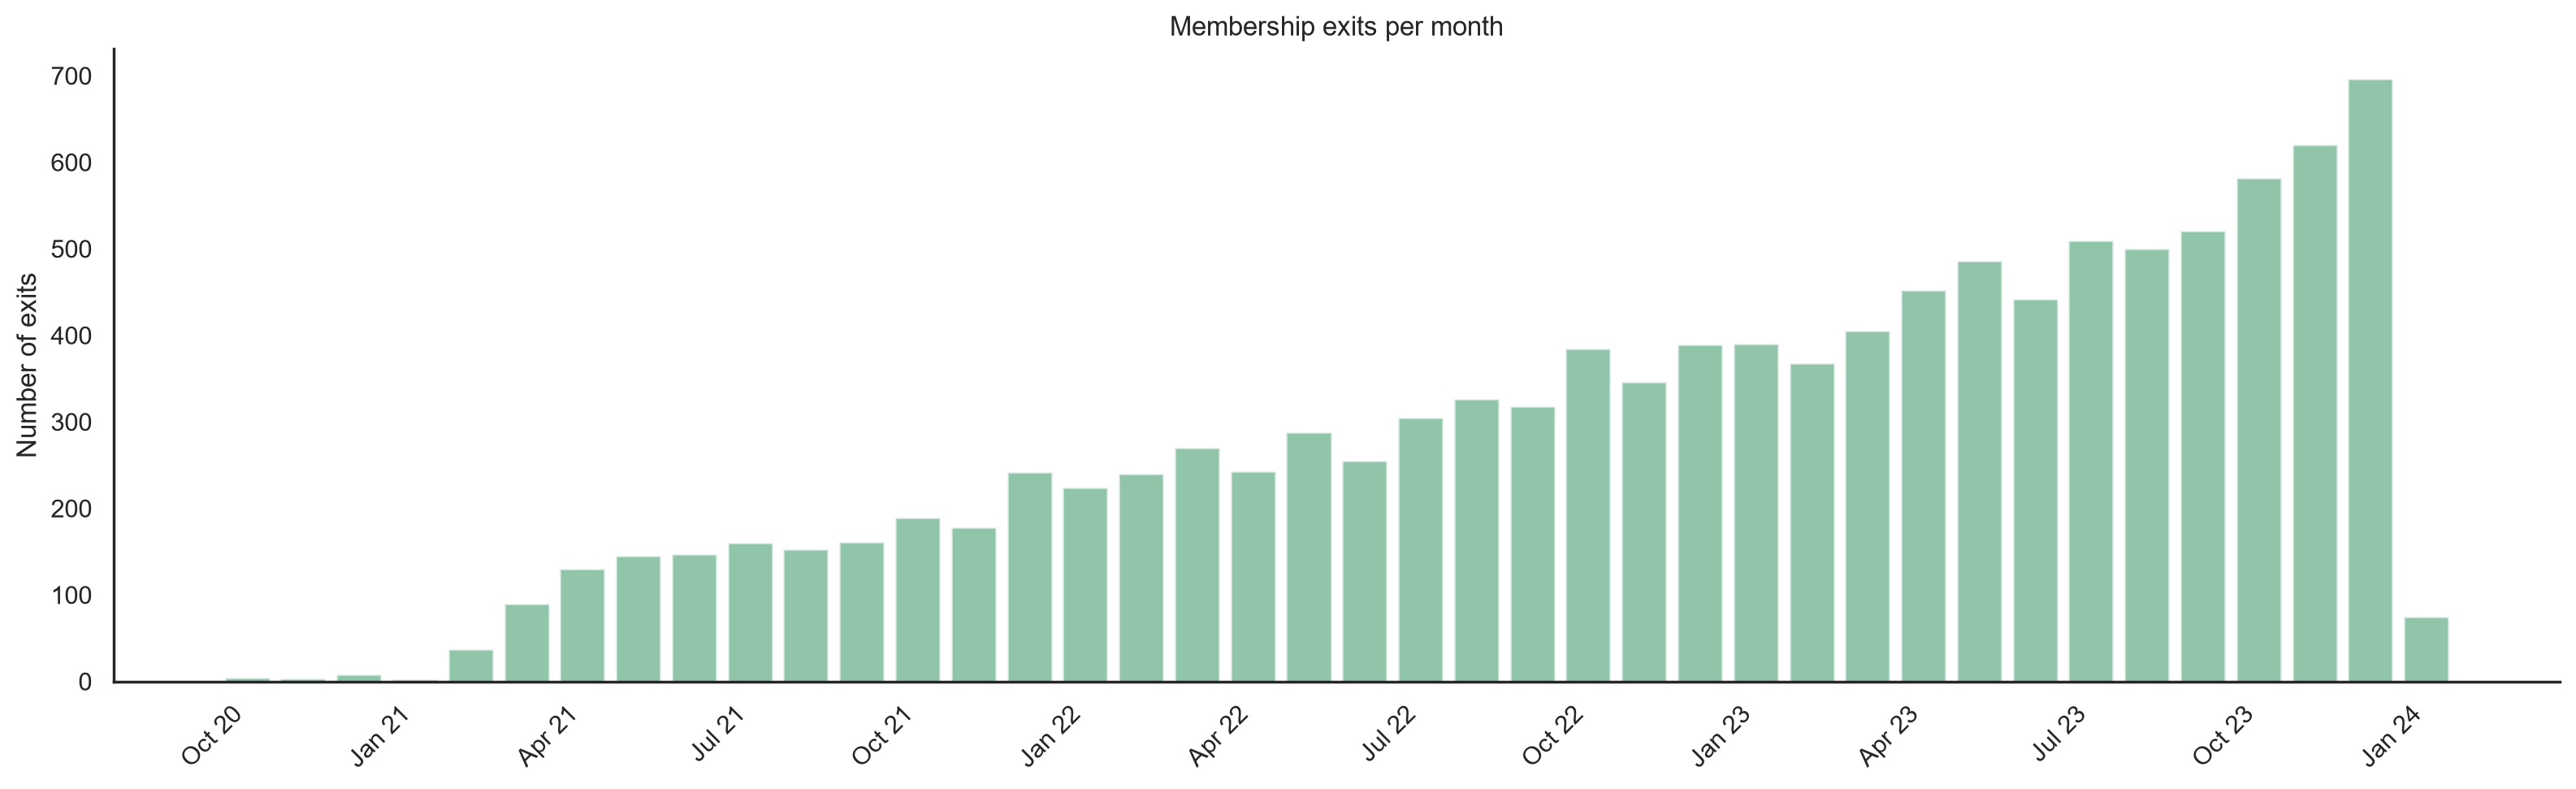

In [47]:
# só saídas reais (exclui o placeholder de 1970)
exits = df.loc[df["membership_end"] != pd.Timestamp("1970-01-01"), "membership_end"]

# nº de saídas por mês (inclui meses com 0)
monthly_exit = exits.to_frame().set_index("membership_end").resample("MS").size()

# tendência suavizada (média móvel de 6 meses)
trend_exit = monthly_exit.rolling(6, center=True, min_periods=1).mean()

labels = monthly_exit.index.strftime("%b %y")

fig, ax = plt.subplots(figsize=(16, 5))

ax.bar(range(len(monthly_exit)), monthly_exit.values, color=main_color, alpha=0.55, width=0.8)
step = 3
ax.set_xticks(range(0, len(monthly_exit), step))
ax.set_xticklabels(labels[::step], rotation=45, ha="right")

ax.set_title("Membership exits per month")
ax.set_xlabel("")
ax.set_ylabel("Number of exits")
sns.despine()
plt.tight_layout()
plt.show()

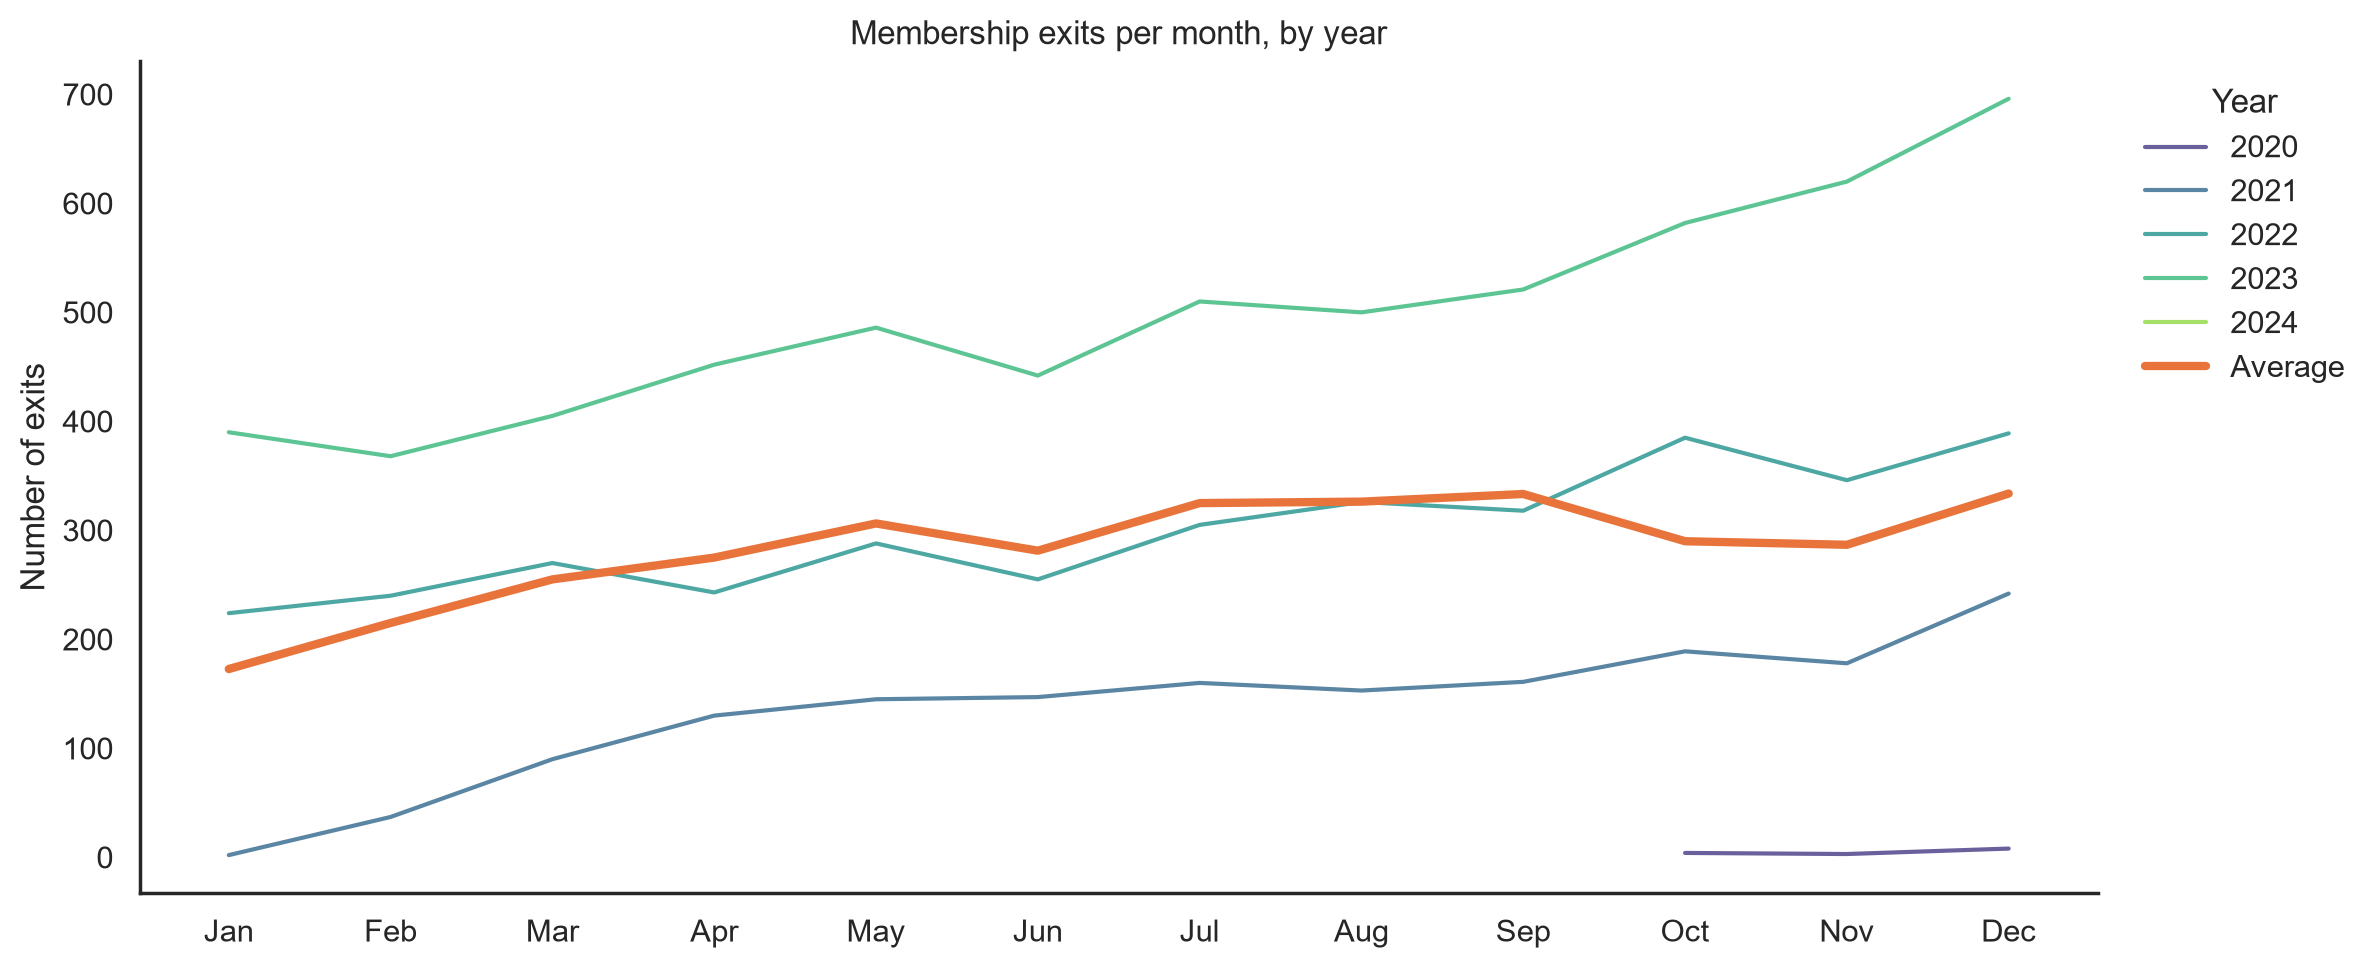

In [48]:
# só saídas reais (exclui o placeholder de 1970)
tmp = df.loc[df["membership_end"] != pd.Timestamp("1970-01-01")].copy()
tmp["year"] = tmp["membership_end"].dt.year
tmp["month"] = tmp["membership_end"].dt.month

# nº de saídas por (ano, mês)
pivot = tmp.pivot_table(index="month", columns="year", values="membership_end", aggfunc="count")

fig, ax = plt.subplots(figsize=(12, 5))

# uma linha fininha por ano
colors_years = sns.color_palette("viridis", n_colors=pivot.shape[1])
for color, year in zip(colors_years, pivot.columns):
    ax.plot(pivot.index, pivot[year], color=color, alpha=0.8, label=str(year))

# média de todos os anos (a "tendência" sazonal)
ax.plot(pivot.index, pivot.mean(axis=1), color="#E8743B", linewidth=3, label="Average")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Membership exits per month, by year")
ax.set_xlabel("")
ax.set_ylabel("Number of exits")
ax.legend(title="Year", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()